<a href="https://colab.research.google.com/github/pavnastia/ecommerce-data-analysis/blob/main/ecommerce_data_analysis_ua.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Sales Performance Overview

[посилання на Tableau](https://public.tableau.com/app/profile/anastasiia.pavlenko/viz/SalesPerformanceOverview_17914707526710/Dashboard1#1)

In [ ]:
#Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

---
# 1. Data overview

In [ ]:
# Import libraries for authentication and BigQuery connection
from google.colab import auth
from google.cloud import bigquery

# Authenticate Google account
auth.authenticate_user()

# Create a connection to the BigQuery project
bq = bigquery.Client(project="data-analytics-mate")

# Write SQL query to create the final dataset
query = """
SELECT
    s.date AS session_date,
    s.ga_session_id AS session_id,
    sp.continent AS continent,
    sp.country AS country,
    sp.device AS device_type,
    sp.browser AS browser,
    sp.mobile_model_name AS mobile_model_name,
    sp.operating_system AS operating_system,
    sp.language AS browser_language,
    sp.name AS traffic_source_info,
    sp.channel AS traffic_channel,
    ac.id AS account_id,
    ac.is_verified AS is_verified,
    ac.is_unsubscribed AS is_unsubscribed,
    p.category AS product_category,
    p.name AS product_name,
    p.price AS product_price,
    p.short_description AS product_short_description
FROM `data-analytics-mate.DA.session` AS s
LEFT JOIN `data-analytics-mate.DA.session_params` AS sp
    ON sp.ga_session_id = s.ga_session_id
LEFT JOIN `data-analytics-mate.DA.account_session` AS acs
    ON acs.ga_session_id = s.ga_session_id
LEFT JOIN `data-analytics-mate.DA.account` AS ac
    ON ac.id = acs.account_id
LEFT JOIN `data-analytics-mate.DA.order` AS o
    ON o.ga_session_id = s.ga_session_id
LEFT JOIN `data-analytics-mate.DA.product` AS p
    ON p.item_id = o.item_id
"""

# Execute the query and load the result into a Pandas DataFrame
df = bq.query(query).to_dataframe(
    create_bqstorage_client=False
)

# Display the first 5 rows of the dataset
df.head()

,session_date,session_id,continent,country,device_type,browser,mobile_model_name,operating_system,browser_language,traffic_source_info,traffic_channel,account_id,is_verified,is_unsubscribed,product_category,product_name,product_price,product_short_description
0,2020-11-01,5760483956,Americas,United States,desktop,Chrome,Safari,Macintosh,zh,<Other>,Paid Search,<NA>,<NA>,<NA>,Bookcases & shelving units,VITTSJÖ,609.0,"Shelving unit with laptop table, 202x36x175 cm"
1,2020-11-01,7115337200,Europe,United Kingdom,desktop,Chrome,Chrome,Web,en-us,(organic),Organic Search,<NA>,<NA>,<NA>,Bookcases & shelving units,VITTSJÖ,609.0,"Shelving unit with laptop table, 202x36x175 cm"
2,2020-11-01,3978035233,Europe,Norway,mobile,Chrome,<Other>,Web,zh,(direct),Direct,<NA>,<NA>,<NA>,Tables & desks,RÅSKOG,189.0,"Trolley, 35x45x78 cm"
3,2020-11-01,9648986282,Africa,Nigeria,mobile,Chrome,<Other>,Android,es-es,(direct),Direct,<NA>,<NA>,<NA>,Bookcases & shelving units,VITTSJÖ,609.0,"Shelving unit with laptop table, 202x36x175 cm"
4,2020-11-01,4393441533,Asia,China,desktop,Chrome,Chrome,Windows,en-us,(direct),Direct,<NA>,<NA>,<NA>,Bookcases & shelving units,VITTSJÖ,609.0,"Shelving unit with laptop table, 202x36x175 cm"


## Data Overview

Датасет містить інформацію про сесії користувачів, їхні пристрої, джерела трафіку, акаунти та придбані товари.

Колонки датасету:

- `session_date` — дата сесії
- `session_id` — ідентифікатор сесії
- `continent` — континент
- `country` — країна
- `device_type` — тип пристрою
- `browser` — браузер
- `mobile_model_name` — модель мобільного пристрою
- `operating_system` — операційна система
- `browser_language` — мова браузера
- `traffic_source_info` — інформація про джерело трафіку
- `traffic_channel` — канал трафіку
- `account_id` — ідентифікатор користувача
- `is_verified` — чи підтверджений email
- `is_unsubscribed` — чи відписався користувач від розсилки
- `product_category` — категорія товару
- `product_name` — назва товару
- `product_price` — ціна товару
- `product_short_description` — короткий опис товару

---

# 2. Data cleaning

In [ ]:
# Check the shape of the dataset: number of rows and columns
print(df.shape)

(349545, 18)


In [ ]:
# Check data types of all columns
print(df.dtypes)

session_date                  dbdate
session_id                     Int64
continent                     object
country                       object
device_type                   object
browser                       object
mobile_model_name             object
operating_system              object
browser_language              object
traffic_source_info           object
traffic_channel               object
account_id                     Int64
is_verified                    Int64
is_unsubscribed                Int64
product_category              object
product_name                  object
product_price                float64
product_short_description     object
dtype: object


In [ ]:
# Count the number of unique sessions
print(df['session_id'].nunique())

349545


In [ ]:
# Check the date range in the dataset
print("Start date:", df['session_date'].min())
print("End date:", df['session_date'].max())

Start date: 2020-11-01
End date: 2021-01-31


In [ ]:
# Check the number of missing values in each column
print(df.isna().sum())

session_date                      0
session_id                        0
continent                         0
country                           0
device_type                       0
browser                           0
mobile_model_name                 0
operating_system                  0
browser_language             114266
traffic_source_info               0
traffic_channel                   0
account_id                   321600
is_verified                  321600
is_unsubscribed              321600
product_category             316007
product_name                 316007
product_price                316007
product_short_description    316007
dtype: int64


In [ ]:
# Check the percentage of missing values in each column
print(df.isna().sum() / df.shape[0] * 100)

session_date                  0.000000
session_id                    0.000000
continent                     0.000000
country                       0.000000
device_type                   0.000000
browser                       0.000000
mobile_model_name             0.000000
operating_system              0.000000
browser_language             32.689925
traffic_source_info           0.000000
traffic_channel               0.000000
account_id                   92.005321
is_verified                  92.005321
is_unsubscribed              92.005321
product_category             90.405241
product_name                 90.405241
product_price                90.405241
product_short_description    90.405241
dtype: float64


In [ ]:
# Check for fully duplicated rows
duplicate_rows = df.duplicated()
print(duplicate_rows)
print(duplicate_rows.sum())

0         False
1         False
2         False
3         False
4         False
          ...  
349540    False
349541    False
349542    False
349543    False
349544    False
Length: 349545, dtype: bool
0


In [ ]:
# Check how many times each session appears in the dataset
print(df['session_id'].value_counts())

session_id
7058940865    1
5760483956    1
7115337200    1
3978035233    1
9648986282    1
             ..
3102126424    1
9065007548    1
492855917     1
6424219101    1
1129172264    1
Name: count, Length: 349545, dtype: Int64


In [ ]:
# Check unique values and their frequency for device types
print(df['device_type'].value_counts(dropna=False))

device_type
desktop    204429
mobile     137267
tablet       7849
Name: count, dtype: int64


In [ ]:
# Check unique values and their frequency for browsers
print(df['browser'].value_counts(dropna=False))

browser
Chrome             238460
Safari              83254
<Other>              8930
Edge                 8023
Firefox              6433
Android Webview      4445
Name: count, dtype: int64


In [ ]:
# Check unique values and their frequency for traffic channels
print(df['traffic_channel'].value_counts(dropna=False))

traffic_channel
Organic Search    124425
Paid Search        94341
Direct             81382
Social Search      27914
Undefined          21483
Name: count, dtype: int64


In [ ]:
# Check how many rows contain product information
print(df['product_name'].notna().value_counts())

product_name
False    316007
True      33538
Name: count, dtype: int64


In [ ]:
# Check whether product prices contain negative values
print((df['product_price'] < 0).sum())

0


In [ ]:
# Check unique values in email verification status
print(df['is_verified'].value_counts(dropna=False))

is_verified
<NA>    321600
1        20036
0         7909
Name: count, dtype: Int64


In [ ]:
# Check unique values in unsubscribe status
print(df['is_unsubscribed'].value_counts(dropna=False))

is_unsubscribed
<NA>    321600
0        23210
1         4735
Name: count, dtype: Int64


In [ ]:
df['browser_language'] = df['browser_language'].fillna('unknown')


In [ ]:
# Check basic statistics for product prices
df['product_price'].describe()

,product_price
count,33538.000000
mean,953.298679
std,1317.001775
min,3.000000
25%,170.000000
50%,445.000000
75%,1195.000000
max,9585.000000


In [ ]:
# Convert session date to datetime format
df['session_date'] = pd.to_datetime(df['session_date'])

print(df.dtypes)

session_date                 datetime64[ns]
session_id                            Int64
continent                            object
country                              object
device_type                          object
browser                              object
mobile_model_name                    object
operating_system                     object
browser_language                     object
traffic_source_info                  object
traffic_channel                      object
account_id                            Int64
is_verified                           Int64
is_unsubscribed                       Int64
product_category                     object
product_name                         object
product_price                       float64
product_short_description            object
dtype: object


##  Data Cleaning
---

Датасет містить **349 545 рядків і 18 колонок**.

- Кількість унікальних сесій: **349 545**
- Період даних: **з 1.11.2020 до 31.01.2021**
- Повних дублікатів у датасеті: **0**
- Колонка `session_date` була приведена до формату `datetime`
- Негативних значень у `product_price` не виявлено
---
### Missing values

Пропущені значення є в кількох колонках:

- `browser_language` — приблизно **32.7%**
- `account_id`, `is_verified`, `is_unsubscribed` — приблизно **92.0%**
- `product_category`, `product_name`, `product_price`, `product_short_description` — приблизно **90.4%**

Пропуски в `browser_language` були замінені на `unknown`.

Пропуски в колонках, пов’язаних з акаунтом, залишені без змін, оскільки вони означають, що користувач не був зареєстрований.

Пропуски в колонках товарів також залишені без змін, оскільки вони означають, що сесія не завершилась покупкою.

---
### Product price

Для товарів, які були придбані:

- мінімальна ціна: **$3**

- медіанна ціна: **$445**

- середня ціна: **$953.30**

- максимальна ціна: **$9585**


Після перевірки дані можна використовувати для подальшого аналізу.

---
# 3. Sales Overview

In [ ]:
# Find top 3 continents by total sales
top_continents_sales = (
    df[df['product_name'].notna()]
    .groupby('continent')['product_price']
    .sum()
    .sort_values(ascending=False)
    .head(3)
)

top_continents_sales

,product_price
continent,
Americas,17665280.0
Asia,7601298.3
Europe,5934624.2


In [ ]:
# Find top 3 continents by number of purchases
top_continents_orders = (
    df[df['product_name'].notna()]
    .groupby('continent')
    .size()
    .sort_values(ascending=False)
    .head(3)
)

top_continents_orders

,0
continent,
Americas,18553
Asia,7950
Europe,6261


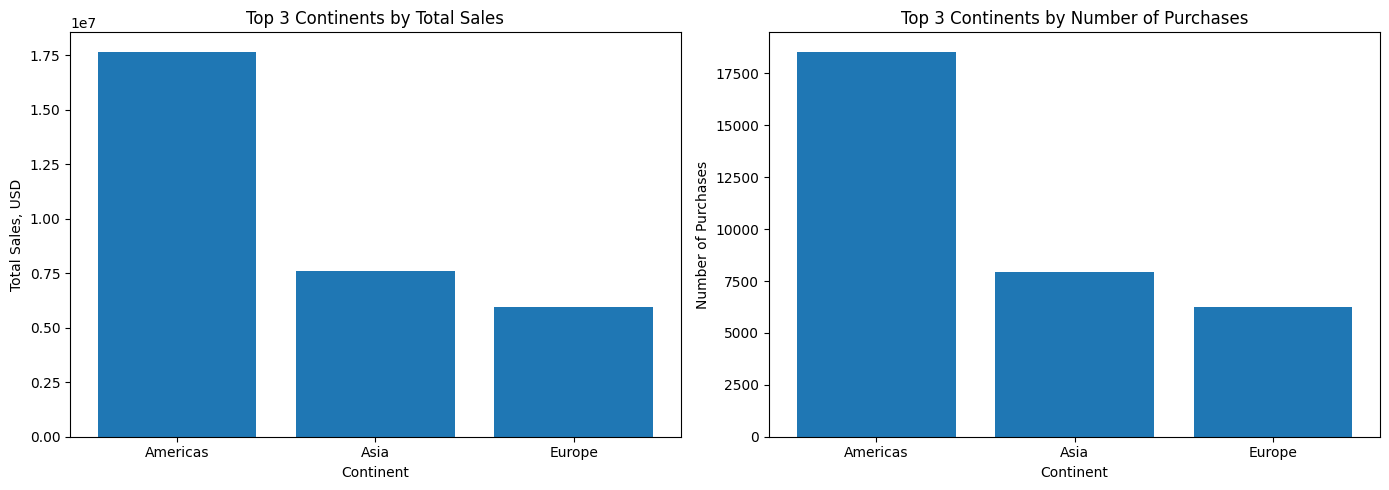

In [ ]:
# Visualize top 3 continents by sales and number of purchases

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Top 3 continents by total sales
axes[0].bar(top_continents_sales.index, top_continents_sales.values)
axes[0].set_title('Top 3 Continents by Total Sales')
axes[0].set_xlabel('Continent')
axes[0].set_ylabel('Total Sales, USD')

# Top 3 continents by number of purchases
axes[1].bar(top_continents_orders.index, top_continents_orders.values)
axes[1].set_title('Top 3 Continents by Number of Purchases')
axes[1].set_xlabel('Continent')
axes[1].set_ylabel('Number of Purchases')

plt.tight_layout()
plt.show()

In [ ]:
# Find top 5 countries by total sales
top_countries_sales = (
    df[df['product_name'].notna()]
    .groupby('country')['product_price']
    .sum()
    .sort_values(ascending=False)
    .head(5)
)

top_countries_sales

,product_price
country,
United States,13943553.9
India,2809762.0
Canada,2437921.0
United Kingdom,938317.9
France,710692.8


In [ ]:
# Find top 5 countries by number of purchases
top_countries_orders = (
    df[df['product_name'].notna()]
    .groupby('country')
    .size()
    .sort_values(ascending=False)
    .head(5)
)

top_countries_orders

,0
country,
United States,14673
India,3029
Canada,2560
United Kingdom,1029
France,678


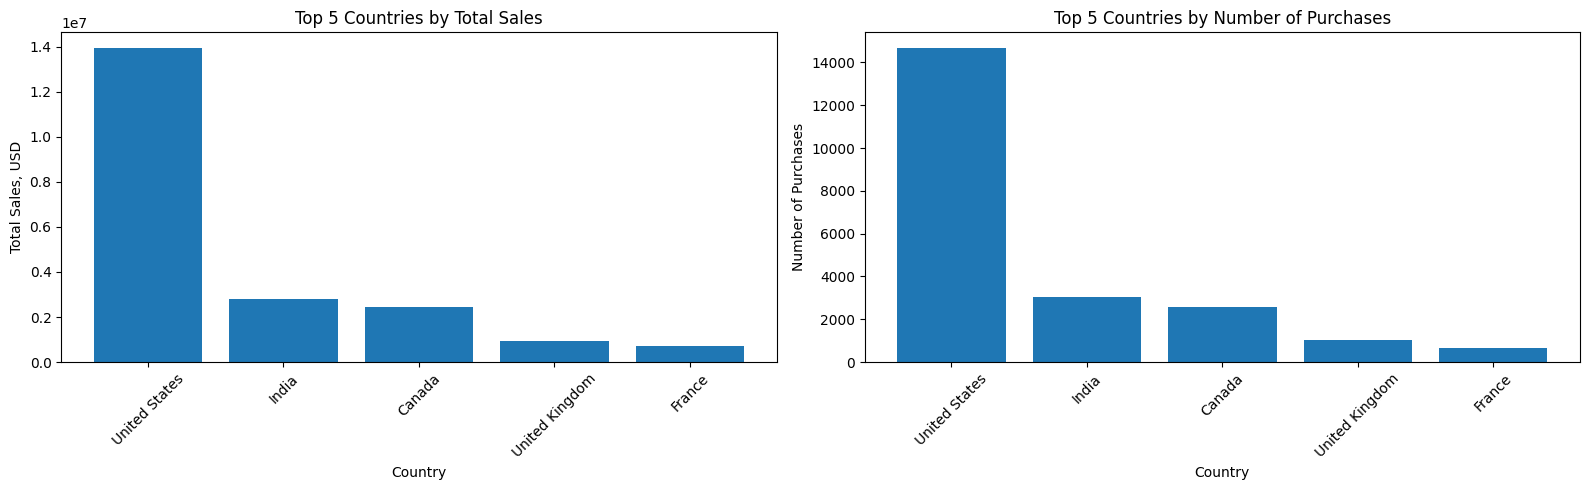

In [ ]:
# Visualize top 5 countries by sales and number of purchases

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Top 5 countries by total sales
axes[0].bar(top_countries_sales.index, top_countries_sales.values)
axes[0].set_title('Top 5 Countries by Total Sales')
axes[0].set_xlabel('Country')
axes[0].set_ylabel('Total Sales, USD')
axes[0].tick_params(axis='x', rotation=45)

# Top 5 countries by number of purchases
axes[1].bar(top_countries_orders.index, top_countries_orders.values)
axes[1].set_title('Top 5 Countries by Number of Purchases')
axes[1].set_xlabel('Country')
axes[1].set_ylabel('Number of Purchases')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
# Find top 10 product categories by total sales
top_categories_sales = (
    df[df['product_name'].notna()]
    .groupby('product_category')['product_price']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_categories_sales

,product_price
product_category,
Sofas & armchairs,8388254.5
Chairs,6147748.8
Beds,4919725.0
Bookcases & shelving units,3640818.1
Cabinets & cupboards,2336499.5
Outdoor furniture,2142222.2
Tables & desks,1790307.5
Chests of drawers & drawer units,906562.5
Bar furniture,735503.0


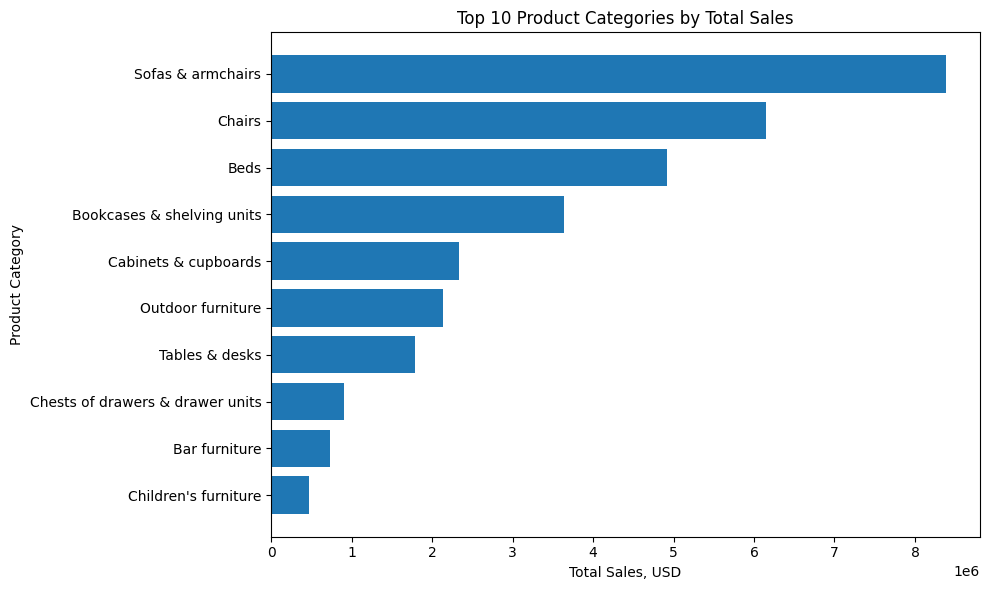

In [ ]:
# Visualize top 10 product categories by total sales
plt.figure(figsize=(10, 6))

plt.barh(
    top_categories_sales.index[::-1],
    top_categories_sales.values[::-1]
)

plt.title('Top 10 Product Categories by Total Sales')
plt.xlabel('Total Sales, USD')
plt.ylabel('Product Category')

plt.tight_layout()
plt.show()

In [ ]:
# Find the country with the highest total sales
top_country = top_countries_sales.index[0]

print("Top country:", top_country)

Top country: United States


In [ ]:
# Find top 10 product categories in the country with the highest sales
top_country_categories = (
    df[
        (df['country'] == top_country) &
        (df['product_name'].notna())
    ]
    .groupby('product_category')['product_price']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_country_categories

,product_price
product_category,
Sofas & armchairs,3707144.5
Chairs,2619773.8
Beds,2213058.0
Bookcases & shelving units,1567606.9
Cabinets & cupboards,994545.5
Outdoor furniture,929245.2
Tables & desks,777865.0
Chests of drawers & drawer units,382388.0
Bar furniture,330805.0


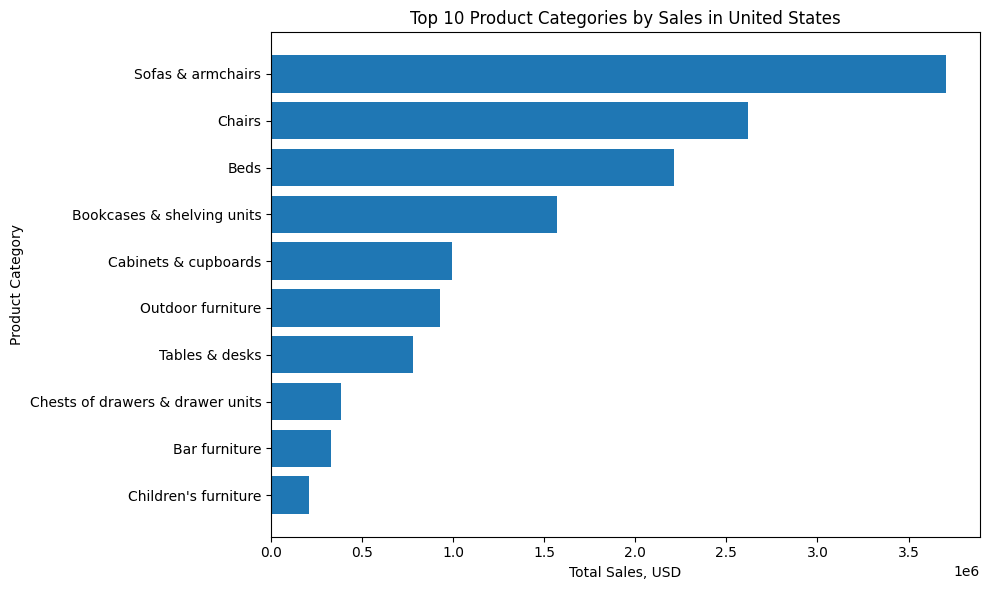

In [ ]:
# Visualize top 10 product categories in the top-selling country
plt.figure(figsize=(10, 6))

plt.barh(
    top_country_categories.index[::-1],
    top_country_categories.values[::-1]
)

plt.title(f'Top 10 Product Categories by Sales in {top_country}')
plt.xlabel('Total Sales, USD')
plt.ylabel('Product Category')

plt.tight_layout()
plt.show()

In [ ]:
# Calculate the share of total sales by device type
device_sales = (
    df[df['product_name'].notna()]
    .groupby('device_type')['product_price']
    .sum()
    .sort_values(ascending=False)
)

device_sales_share = device_sales / device_sales.sum() * 100

device_sales_share

,product_price
device_type,
desktop,59.002245
mobile,38.734924
tablet,2.262831


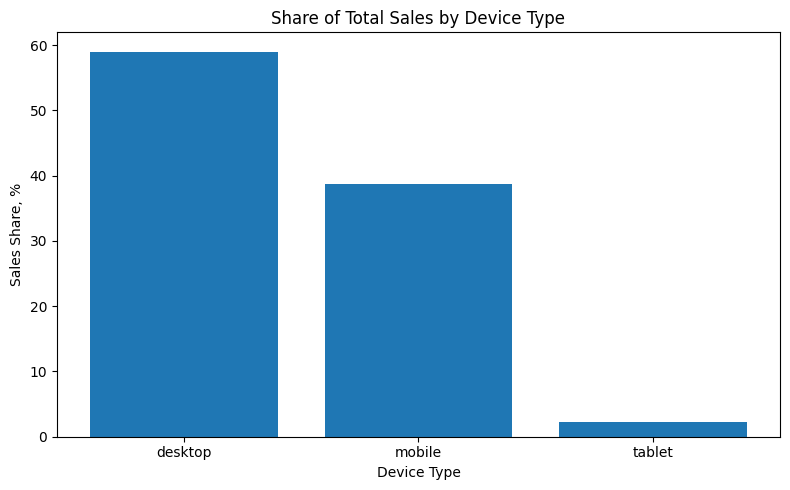

In [ ]:
# Visualize the share of total sales by device type
plt.figure(figsize=(8, 5))

plt.bar(device_sales_share.index, device_sales_share.values)

plt.title('Share of Total Sales by Device Type')
plt.xlabel('Device Type')
plt.ylabel('Sales Share, %')

plt.tight_layout()
plt.show()

In [ ]:
# Find top 10 device models by total sales
top_device_models = (
    df[df['product_name'].notna()]
    .groupby('mobile_model_name')['product_price']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_device_models

,product_price
mobile_model_name,
Chrome,8899523.9
<Other>,6535330.8
Safari,6491062.1
iPhone,6420776.3
ChromeBook,1830458.7
Edge,697222.3
iPad,448854.2
Firefox,421066.9
Pixel 4 XL,118287.7


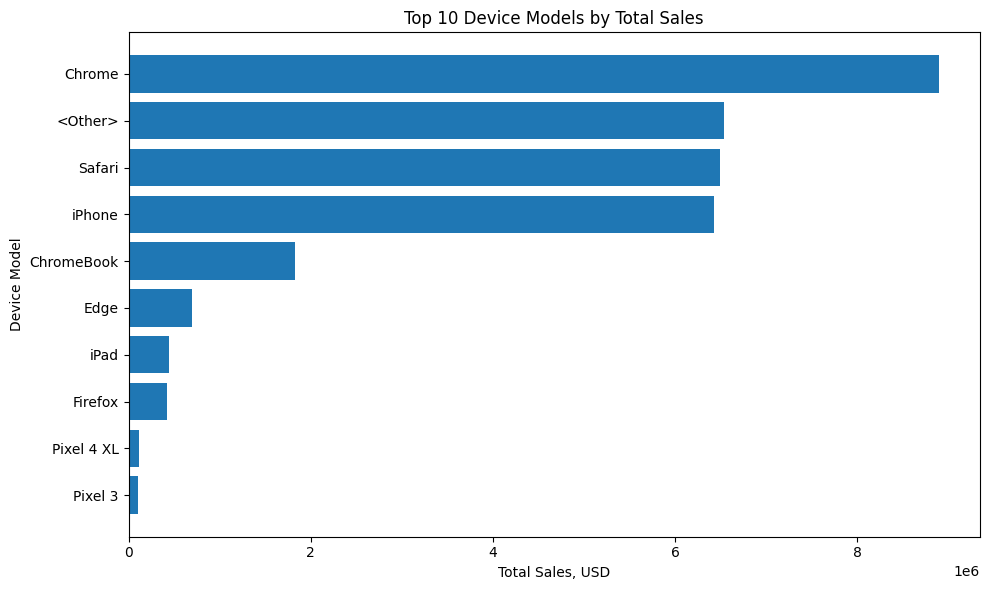

In [ ]:
# Visualize top 10 device models by total sales
plt.figure(figsize=(10, 6))

plt.barh(
    top_device_models.index[::-1],
    top_device_models.values[::-1]
)

plt.title('Top 10 Device Models by Total Sales')
plt.xlabel('Total Sales, USD')
plt.ylabel('Device Model')

plt.tight_layout()
plt.show()

In [ ]:
# Calculate the share of total sales by traffic channel
traffic_sales = (
    df[df['product_name'].notna()]
    .groupby('traffic_channel')['product_price']
    .sum()
    .sort_values(ascending=False)
)

traffic_sales_share = traffic_sales / traffic_sales.sum() * 100

traffic_sales_share

,product_price
traffic_channel,
Organic Search,35.760189
Paid Search,26.620546
Direct,23.442345
Social Search,7.919827
Undefined,6.257093


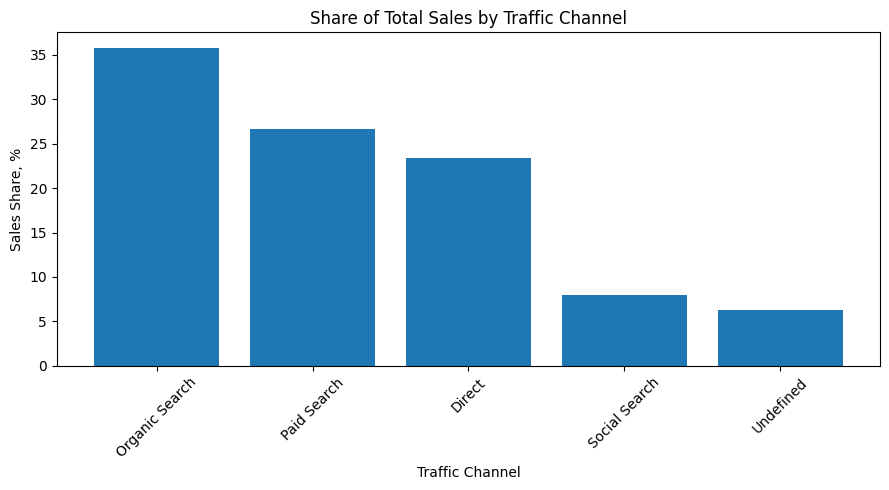

In [ ]:
# Visualize the share of total sales by traffic channel
plt.figure(figsize=(9, 5))

plt.bar(traffic_sales_share.index, traffic_sales_share.values)

plt.title('Share of Total Sales by Traffic Channel')
plt.xlabel('Traffic Channel')
plt.ylabel('Sales Share, %')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
# Create a dataset with unique registered users
registered_users = (
    df[df['account_id'].notna()]
    [['account_id', 'is_verified', 'is_unsubscribed']]
    .drop_duplicates(subset='account_id')
)

registered_users.head()

,account_id,is_verified,is_unsubscribed
28,649280,1,1
50,676055,1,1
58,677981,0,0
80,672927,1,0
96,653089,1,0


In [ ]:
# Calculate the percentage of registered users with verified email
verified_share = registered_users['is_verified'].mean() * 100

print(f"Verified users: {verified_share:.2f}%")

Verified users: 71.70%


In [ ]:
# Calculate the percentage of registered users who unsubscribed
unsubscribed_share = registered_users['is_unsubscribed'].mean() * 100

print(f"Unsubscribed users: {unsubscribed_share:.2f}%")

Unsubscribed users: 16.94%


In [ ]:
# Find countries with the highest number of registered users
registered_users_by_country = (
    df[df['account_id'].notna()]
    .groupby('country')['account_id']
    .nunique()
    .sort_values(ascending=False)
    .head(10)
)

registered_users_by_country

,account_id
country,
United States,12384
India,2687
Canada,2067
United Kingdom,859
France,553
Spain,536
Taiwan,500
China,490
Germany,490


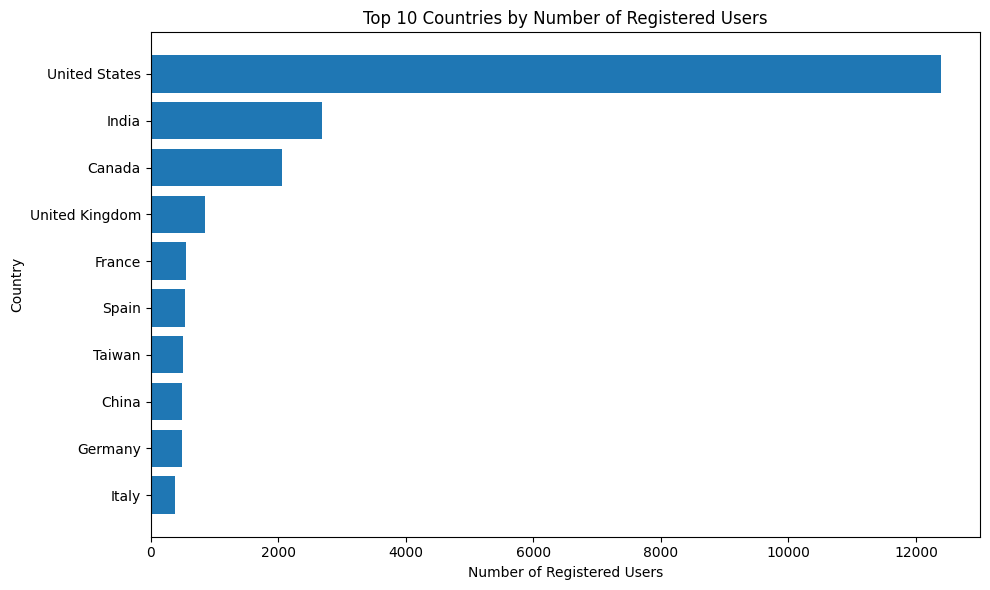

In [ ]:
# Visualize countries with the highest number of registered users
plt.figure(figsize=(10, 6))

plt.barh(
    registered_users_by_country.index[::-1],
    registered_users_by_country.values[::-1]
)

plt.title('Top 10 Countries by Number of Registered Users')
plt.xlabel('Number of Registered Users')
plt.ylabel('Country')

plt.tight_layout()
plt.show()

In [ ]:
# Calculate purchase conversion rate by device type
device_conversion = (
    df.groupby('device_type')
    .agg(
        sessions=('session_id', 'nunique'),
        purchases=('product_name', lambda x: x.notna().sum())
    )
)

device_conversion['conversion_rate'] = (
    device_conversion['purchases'] /
    device_conversion['sessions'] * 100
)

device_conversion.sort_values('conversion_rate', ascending=False)

,sessions,purchases,conversion_rate
device_type,,,
desktop,204429,19702,9.637576
mobile,137267,13113,9.552915
tablet,7849,723,9.211365


In [ ]:
# Calculate average purchase value by traffic channel
traffic_avg_order = (
    df[df['product_name'].notna()]
    .groupby('traffic_channel')['product_price']
    .mean()
    .sort_values(ascending=False)
)

traffic_avg_order

,product_price
traffic_channel,
Undefined,971.588635
Direct,960.887615
Organic Search,959.076554
Paid Search,941.279518
Social Search,932.292231


In [ ]:
# Compare total sales of registered and unregistered users
registration_sales = (
    df.assign(
        user_type=df['account_id'].notna()
        .map({True: 'Registered', False: 'Unregistered'})
    )
    .groupby('user_type')['product_price']
    .sum()
)

registration_sales

,product_price
user_type,
Registered,2582518.5
Unregistered,29389212.6


## Sales Overview

- **Americas** є головним ринком компанії: близько **$17.7M продажів** і **18.6K покупок**. Далі йдуть **Asia** та **Europe**.

- Серед країн беззаперечним лідером є **United States** — близько **$13.9M продажів** і **14.7K покупок**. Наступні позиції займають India, Canada, United Kingdom та France.

- Найбільше доходу приносить категорія **Sofas & armchairs**, за нею йдуть **Chairs** та **Beds**. У США структура топ-категорій майже повторює загальний рейтинг.
- **Desktop** генерує близько **59% продажів**, mobile — **38.7%**, tablet — лише **2.3%**. При цьому conversion rate майже однаковий для всіх типів пристроїв: близько **9–10%**.
- Найбільшу частку продажів приносить **Organic Search (35.8%)**, далі — **Paid Search (26.6%)** та **Direct (23.4%)**.
- Серед зареєстрованих користувачів **71.7% підтвердили email**, а **16.9% відписалися від розсилки**.
- Найбільше зареєстрованих користувачів знаходиться у **United States (12,384)**, далі — India та Canada.

- Загальні продажі незареєстрованих користувачів значно вищі: **\$29.4M** проти **\$2.6M** у зареєстрованих користувачів. Це насамперед пов'язано з тим, що незареєстрованих користувачів у датасеті значно більше.

- Середня сума покупки за різними каналами трафіку відрізняється незначно та знаходиться приблизно в межах **$932 – \$972**.

---

# 4. Sales Dynamics

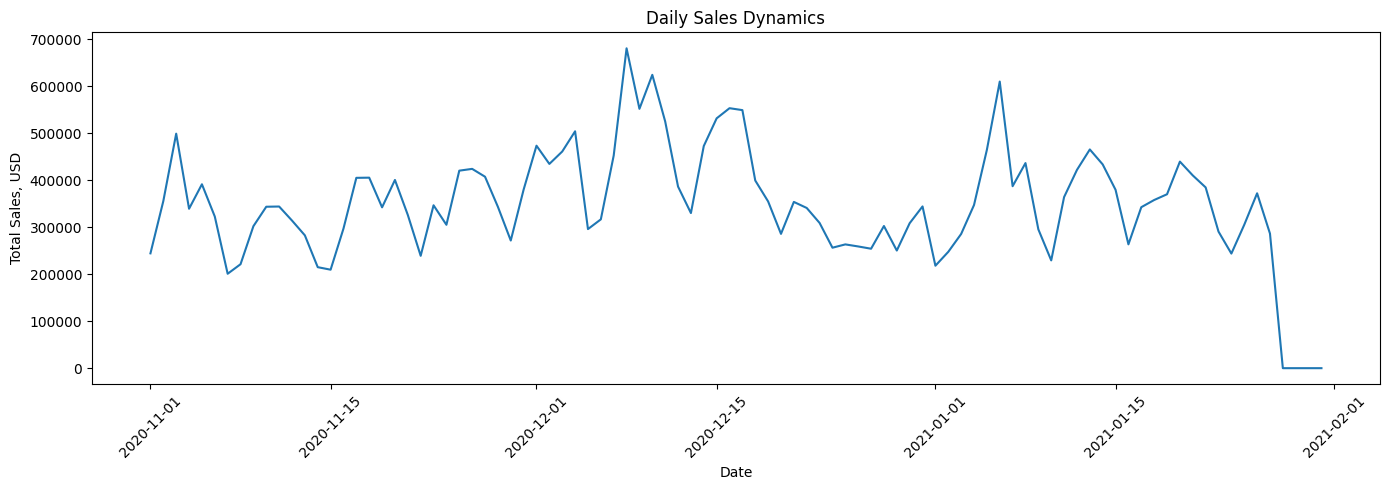

In [ ]:
# Calculate total sales for each date
daily_sales = (
    df.groupby('session_date')['product_price']
    .sum()
    .sort_index())

# Visualize daily sales dynamics
plt.figure(figsize=(14, 5))

plt.plot(daily_sales.index, daily_sales.values)

plt.title('Daily Sales Dynamics')
plt.xlabel('Date')
plt.ylabel('Total Sales, USD')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
# Find dates with the highest sales
top_sales_days = daily_sales.sort_values(ascending=False).head(5)

top_sales_days

,product_price
session_date,
2020-12-08,680509.5
2020-12-10,624104.6
2021-01-06,609763.8
2020-12-16,553134.9
2020-12-09,551811.6


In [ ]:
# Find dates with the lowest sales
lowest_sales_days = daily_sales.sort_values().head(5)

lowest_sales_days

,product_price
session_date,
2021-01-31,0.0
2021-01-30,0.0
2021-01-29,0.0
2021-01-28,0.0
2020-11-07,200892.2


In [ ]:
# Add day of week
df['day_of_week'] = df['session_date'].dt.day_name()

weekday_sales = (
    df.groupby('day_of_week')['product_price']
    .sum()
)

weekday_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

weekday_sales = weekday_sales.reindex(weekday_order)

weekday_sales

,product_price
day_of_week,
Monday,4636290.4
Tuesday,5457515.9
Wednesday,5466542.9
Thursday,4936935.6
Friday,4523067.2
Saturday,3477990.9
Sunday,3473388.2


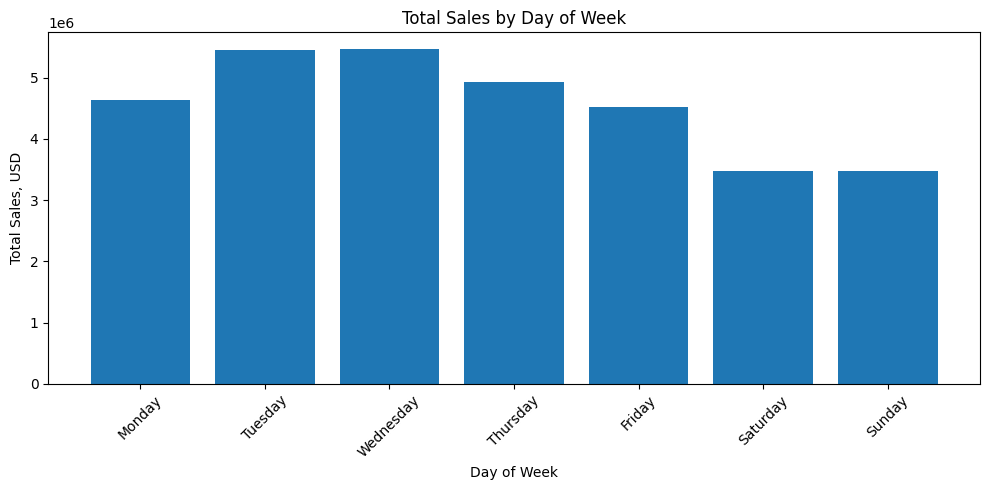

In [ ]:
# Visualize sales by day of week
plt.figure(figsize=(10, 5))

plt.bar(weekday_sales.index, weekday_sales.values)

plt.title('Total Sales by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Total Sales, USD')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

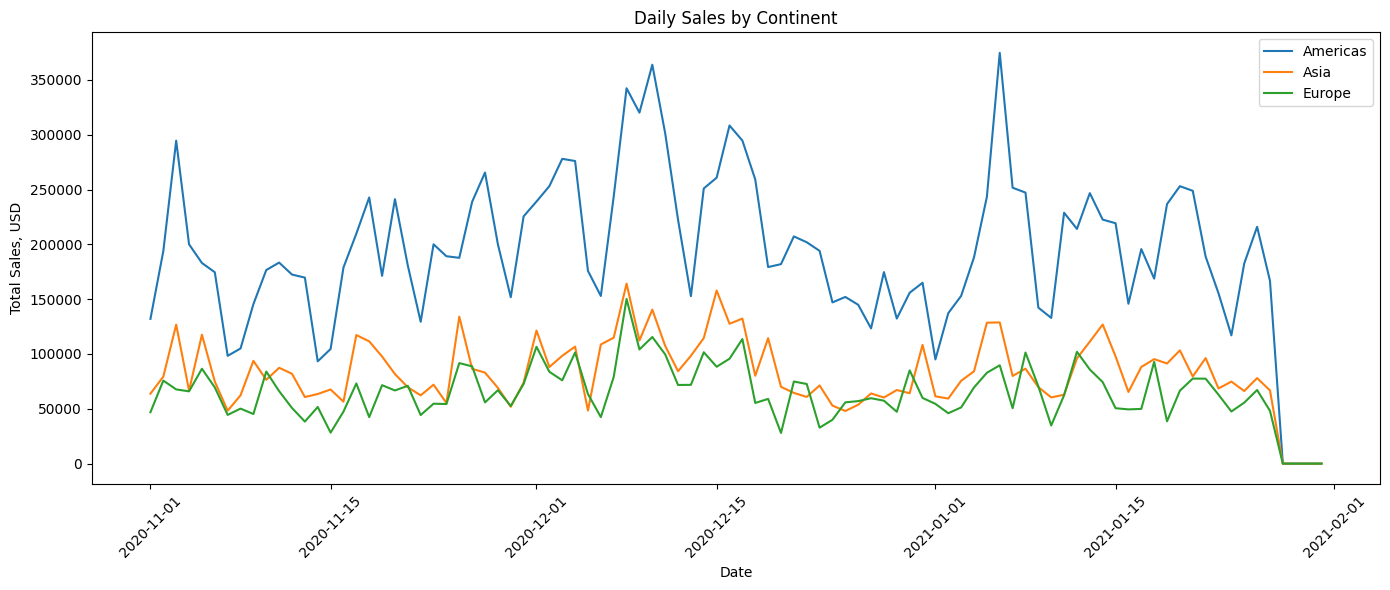

In [ ]:
# Calculate daily sales for Americas, Asia and Europe
continent_daily_sales = (
    df[df['continent'].isin(['Americas', 'Asia', 'Europe'])]
    .groupby(['session_date', 'continent'])['product_price']
    .sum()
    .unstack(fill_value=0))

# Visualize daily sales dynamics by continent
plt.figure(figsize=(14, 6))

for continent in continent_daily_sales.columns:
    plt.plot(
        continent_daily_sales.index,
        continent_daily_sales[continent],
        label=continent
    )

plt.title('Daily Sales by Continent')
plt.xlabel('Date')
plt.ylabel('Total Sales, USD')
plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

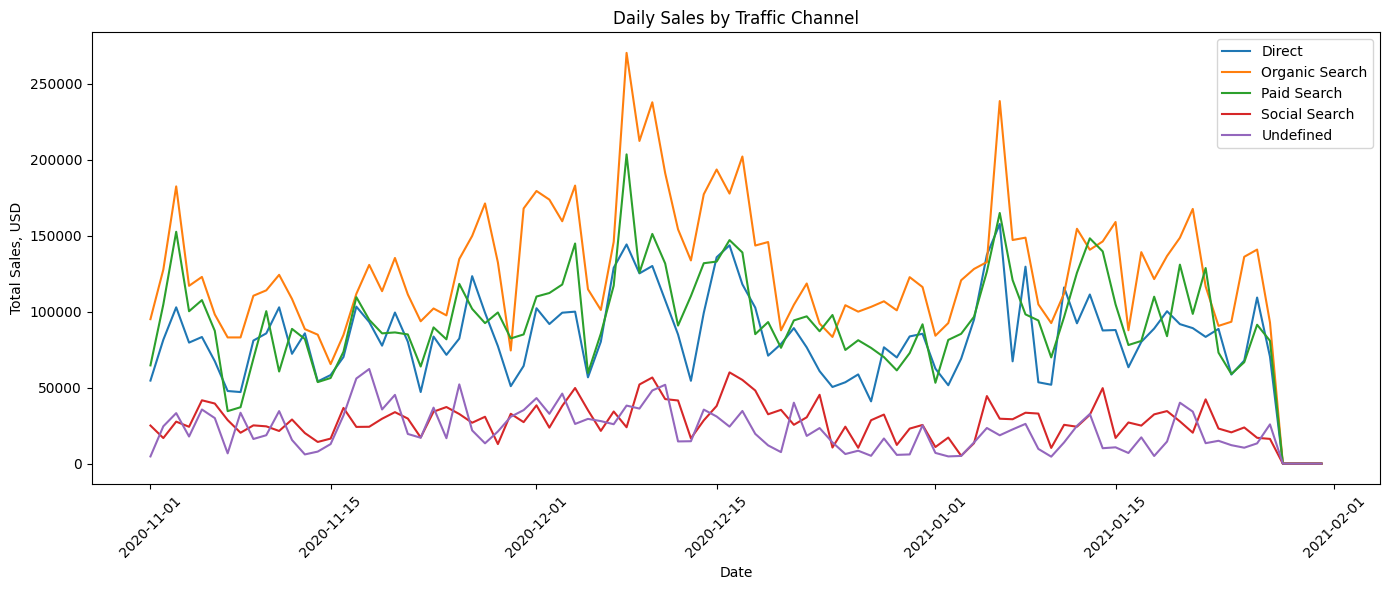

In [ ]:
# Calculate daily sales by traffic channel
traffic_daily_sales = (
    df.groupby(['session_date', 'traffic_channel'])['product_price']
    .sum()
    .unstack(fill_value=0))

# Visualize sales dynamics by traffic channel
plt.figure(figsize=(14, 6))

for channel in traffic_daily_sales.columns:
    plt.plot(
        traffic_daily_sales.index,
        traffic_daily_sales[channel],
        label=channel
    )

plt.title('Daily Sales by Traffic Channel')
plt.xlabel('Date')
plt.ylabel('Total Sales, USD')
plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

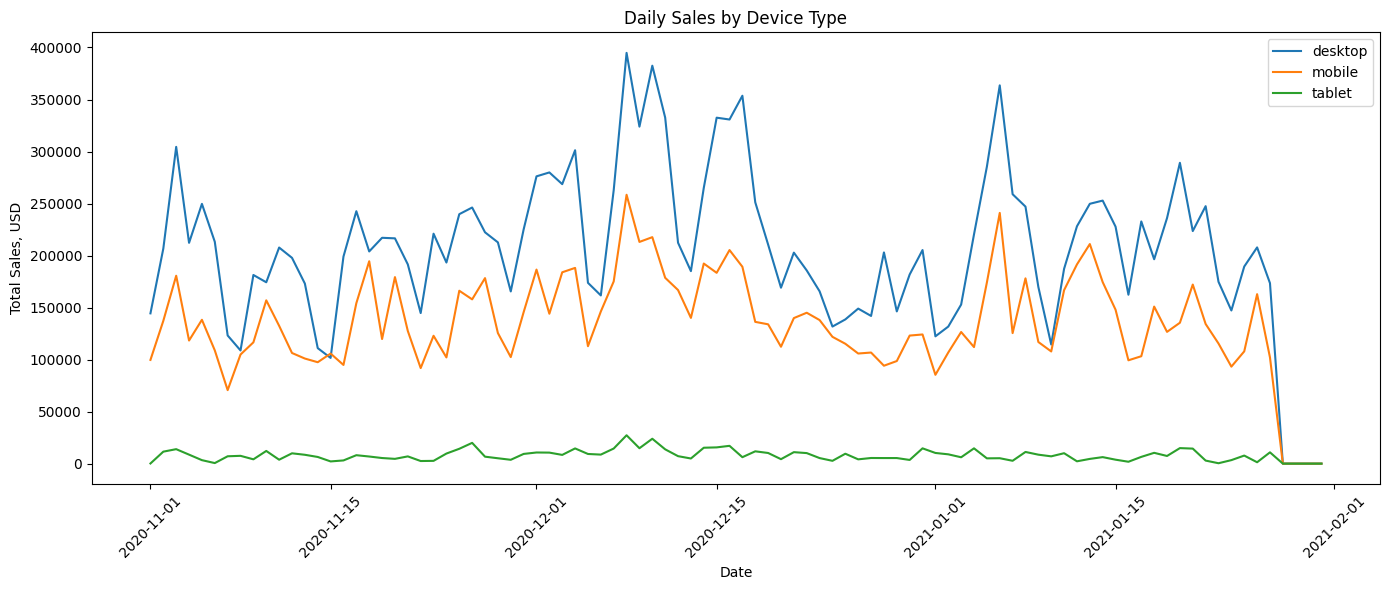

In [ ]:
# Calculate daily sales by device type
device_daily_sales = (
    df.groupby(['session_date', 'device_type'])['product_price']
    .sum()
    .unstack(fill_value=0))

# Visualize sales dynamics by device type
plt.figure(figsize=(14, 6))

for device in device_daily_sales.columns:
    plt.plot(
        device_daily_sales.index,
        device_daily_sales[device],
        label=device
    )

plt.title('Daily Sales by Device Type')
plt.xlabel('Date')
plt.ylabel('Total Sales, USD')
plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

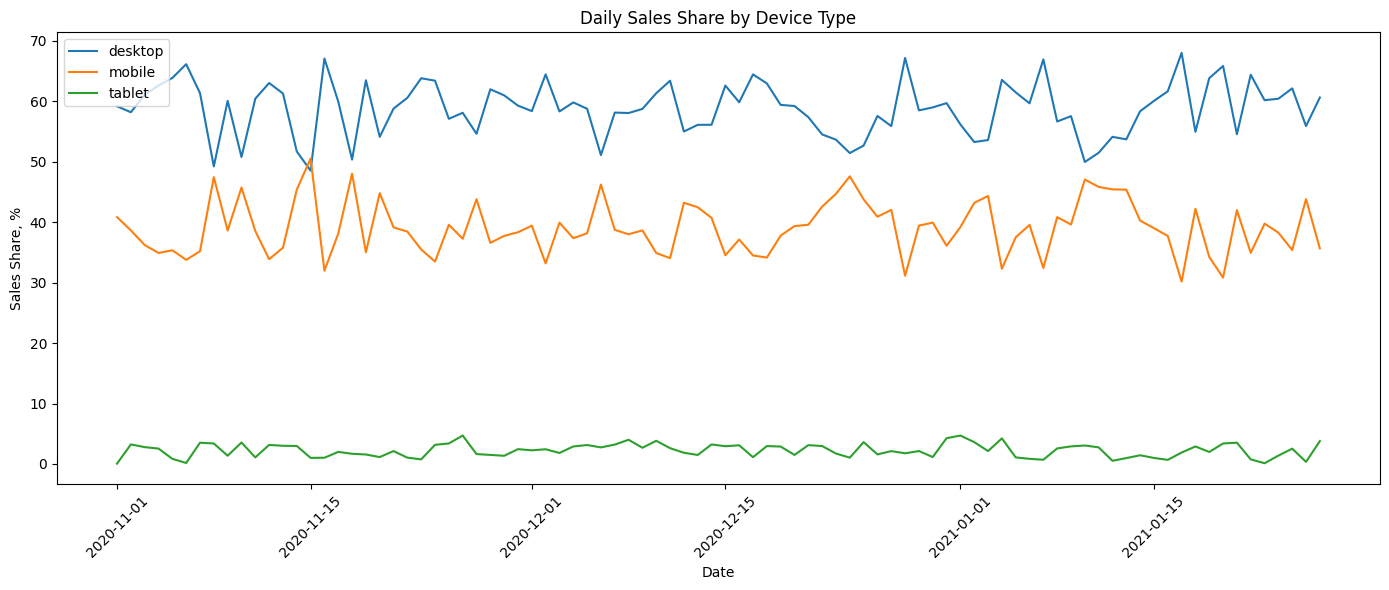

In [ ]:
# Calculate daily sales share by device type
device_sales_share_daily = (
    device_daily_sales
    .div(device_daily_sales.sum(axis=1), axis=0)
    * 100
)

# Visualize daily sales share by device type
plt.figure(figsize=(14, 6))

for device in device_sales_share_daily.columns:
    plt.plot(
        device_sales_share_daily.index,
        device_sales_share_daily[device],
        label=device
    )

plt.title('Daily Sales Share by Device Type')
plt.xlabel('Date')
plt.ylabel('Sales Share, %')
plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()



## Sales Dynamics

- Щоденні продажі помітно коливаються протягом усього періоду, без стабільного довгострокового тренду зростання або падіння.
- Найвищі продажі були зафіксовані **8 грудня 2020 року** — близько **\$680.5K**. Серед інших пікових дат — 10 грудня, 16 грудня та 6 січня.
- Наприкінці січня 2021 року продажі дорівнюють нулю, тому ці дати варто трактувати обережно — це може бути пов'язано з неповними даними за останні дні періоду.
- За днями тижня найбільші обсяги продажів припадають на **Tuesday** та **Wednesday**, а найнижчі — на **Saturday** та **Sunday**. Це вказує на можливий тижневий патерн.
- **Americas** стабільно мають найвищий рівень щоденних продажів. Динаміка Asia та Europe значно нижча, але загалом їхні піки та спади часто відбуваються приблизно в ті самі періоди.
- Серед каналів трафіку найбільші щоденні продажі переважно генерує **Organic Search**, далі — **Paid Search** та **Direct**. Social Search та Undefined мають значно нижчі показники.
- За типами пристроїв **desktop** стабільно генерує найбільший обсяг продажів, mobile займає друге місце, а tablet має мінімальну частку.
- Частка продажів за типами пристроїв протягом часу залишається відносно стабільною: desktop переважно формує близько **50–65%**, mobile — приблизно **30–50%**, а tablet — лише кілька відсотків.


---
# 5. Pivot Tables

In [ ]:
# Exclude rows with unknown traffic channel
filtered_df = df[df['traffic_channel'] != 'Undefined']

# Create a pivot table with the number of sessions by traffic channel and device type
pivot_sessions = pd.pivot_table(
    filtered_df,
    index='traffic_channel',
    columns='device_type',
    values='session_id',
    aggfunc='nunique',
    fill_value=0
)

pivot_sessions

device_type,desktop,mobile,tablet
traffic_channel,,,
Direct,47825,31745,1812
Organic Search,72622,49014,2789
Paid Search,55167,37034,2140
Social Search,16288,10988,638


In [ ]:
# Find combinations of traffic channel and device type with the highest number of sessions
top_session_combinations = (
    filtered_df
    .groupby(['traffic_channel', 'device_type'])['session_id']
    .nunique()
    .sort_values(ascending=False)
    .reset_index(name='sessions')
)

top_session_combinations.head(10)

,traffic_channel,device_type,sessions
0,Organic Search,desktop,72622
1,Paid Search,desktop,55167
2,Organic Search,mobile,49014
3,Direct,desktop,47825
4,Paid Search,mobile,37034
5,Direct,mobile,31745
6,Social Search,desktop,16288
7,Social Search,mobile,10988
8,Organic Search,tablet,2789
9,Paid Search,tablet,2140


In [ ]:
# Identify top 10 product categories by total sales
top_10_categories = (
    df.groupby('product_category')['product_price']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .index
)

# Identify top 5 countries by total sales
top_5_countries = (
    df.groupby('country')['product_price']
    .sum()
    .sort_values(ascending=False)
    .head(5)
    .index
)

# Create a pivot table of sales by top categories and top countries
pivot_category_country = pd.pivot_table(
    df[
        df['product_category'].isin(top_10_categories) &
        df['country'].isin(top_5_countries)
    ],
    index='product_category',
    columns='country',
    values='product_price',
    aggfunc='sum',
    fill_value=0
)

pivot_category_country

country,Canada,France,India,United Kingdom,United States
product_category,,,,,
Bar furniture,51724.0,11199.0,57657.0,22103.0,330805.0
Beds,354772.0,116414.0,358319.5,133816.0,2213058.0
Bookcases & shelving units,278981.9,73830.0,364507.4,113987.6,1567606.9
Cabinets & cupboards,181802.0,59101.5,191888.0,71684.5,994545.5
Chairs,417740.8,134029.4,544309.2,188519.4,2619773.8
Chests of drawers & drawer units,71952.0,21544.5,73111.0,36784.0,382388.0
Children's furniture,30264.0,14258.0,39177.0,13348.0,207575.0
Outdoor furniture,185322.8,40486.4,162289.4,57002.4,929245.2
Sofas & armchairs,692427.5,187735.0,788430.0,234812.0,3707144.5


In [ ]:
# Create a pivot table with total sales by traffic channel and device type
pivot_sales = pd.pivot_table(
    df,
    index='traffic_channel',
    columns='device_type',
    values='product_price',
    aggfunc='sum',
    fill_value=0
)

pivot_sales

device_type,desktop,mobile,tablet
traffic_channel,,,
Direct,4472609.4,2875317.9,146996.1
Organic Search,6794107.8,4408875.1,230168.7
Paid Search,4976977.8,3330032.6,204039.0
Social Search,1447384.8,1006707.3,78013.6
Undefined,1172959.2,763292.9,64248.9


## Pivot Tables

- Найбільша кількість сесій припадає на комбінацію **Organic Search + desktop** — **72,622 сесії**. Далі йдуть **Paid Search + desktop (55,167)** та **Organic Search + mobile (49,014)**.
- У всіх каналах трафіку **desktop** має найбільшу кількість сесій, mobile займає друге місце, а tablet використовується значно рідше.
- Серед топ-5 країн **United States** значно випереджає інші країни за продажами практично в усіх топових категоріях товарів.
- Найбільші продажі серед топ-категорій у більшості країн припадають на **Sofas & armchairs**, а також високі показники мають **Chairs** та **Beds**.
- Найбільший обсяг продажів генерує комбінація **Organic Search + desktop** — близько **\$6.79M**. Наступними є **Paid Search + desktop** та **Organic Search + mobile**.
- Загалом структура продажів підтверджує попередні результати: **Organic Search** є найсильнішим каналом, а **desktop** — основним типом пристрою як за кількістю сесій, так і за сумою продажів.

---
# 6. Statistical Relationships

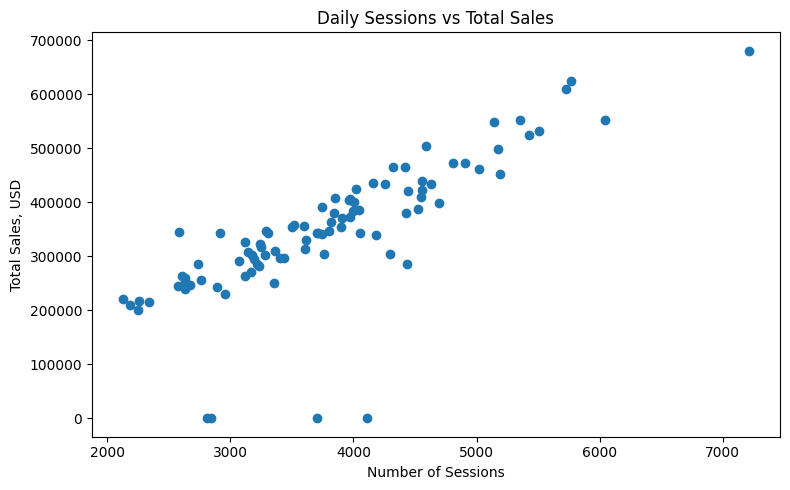

In [ ]:
# Calculate daily number of sessions and total sales
daily_metrics = (
    df.groupby('session_date')
    .agg(
        sessions=('session_id', 'nunique'),
        total_sales=('product_price', 'sum')
    )
    .reset_index()
)

# Visualize the relationship between daily sessions and total sales
plt.figure(figsize=(8, 5))

plt.scatter(
    daily_metrics['sessions'],
    daily_metrics['total_sales']
)

plt.title('Daily Sessions vs Total Sales')
plt.xlabel('Number of Sessions')
plt.ylabel('Total Sales, USD')

plt.tight_layout()
plt.show()

In [ ]:
# Import statistical function for correlation analysis
from scipy.stats import pearsonr

# Calculate Pearson correlation between daily sessions and total sales
corr_sessions_sales, p_sessions_sales = pearsonr(
    daily_metrics['sessions'],
    daily_metrics['total_sales']
)

print(f"Pearson correlation: {corr_sessions_sales:.3f}")
print(f"P-value: {p_sessions_sales:.5f}")

Pearson correlation: 0.791
P-value: 0.00000


---

## Daily Sessions vs Total Sales

Між кількістю сесій за день і загальними щоденними продажами спостерігається **сильний позитивний лінійний зв’язок**.

- Коефіцієнт кореляції Пірсона: **r = 0.791**
- Статистична значущість: **p < 0.05**

Отже, кореляція є **статистично значущою**: зі збільшенням кількості сесій загальні продажі, як правило, також зростають.

Водночас кореляція не означає причинно-наслідковий зв’язок — вона лише показує, що ці дві метрики змінюються разом.

---

In [ ]:
# Calculate daily sales for the top 3 continents
top_3_continents = ['Americas', 'Asia', 'Europe']

continent_sales_daily = (
    df[df['continent'].isin(top_3_continents)]
    .groupby(['session_date', 'continent'])['product_price']
    .sum()
    .unstack(fill_value=0)
)

continent_sales_daily.head()

continent,Americas,Asia,Europe
session_date,,,
2020-11-01,132002.5,63823.0,46908.0
2020-11-02,193861.0,79370.0,75710.8
2020-11-03,294529.8,126737.8,67692.0
2020-11-04,200009.5,66602.0,65915.0
2020-11-05,182988.2,117608.4,86540.0


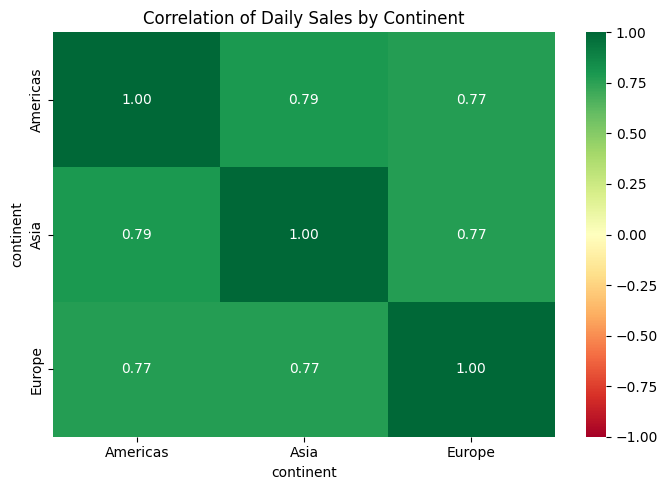

In [ ]:
# Visualize correlation matrix with red-to-green color scale
plt.figure(figsize=(7, 5))

sns.heatmap(
    continent_corr,
    annot=True,
    fmt='.2f',
    cmap='RdYlGn',
    vmin=-1,
    vmax=1,
    center=0
)

plt.title('Correlation of Daily Sales by Continent')
plt.tight_layout()
plt.show()

In [ ]:
# Calculate Pearson correlation and p-value for each pair of continents
continents = continent_sales_daily.columns

for i in range(len(continents)):
    for j in range(i + 1, len(continents)):

        r, p = pearsonr(
            continent_sales_daily[continents[i]],
            continent_sales_daily[continents[j]]
        )

        print(
            f"{continents[i]} vs {continents[j]}: "
            f"r = {r:.3f}, p-value = {p:.3e}"
        )

Americas vs Asia: r = 0.792, p-value = 5.409e-21
Americas vs Europe: r = 0.771, p-value = 2.671e-19
Asia vs Europe: r = 0.768, p-value = 3.865e-19


---

## Daily Sales Correlation by Continent

Продажі на трьох основних континентах мають **сильну позитивну кореляцію**:

- Americas vs Asia: **r = 0.792**
- Americas vs Europe: **r = 0.771**
- Asia vs Europe: **r = 0.768**

Усі взаємозв’язки є **статистично значущими** (`p < 0.05`).

Це означає, що динаміка продажів на Americas, Asia та Europe є схожою: зростання або падіння продажів на одному континенті часто супроводжується аналогічними змінами на інших.

---

In [ ]:
# Calculate daily sales by traffic channel
traffic_sales_daily = (
    df.groupby(['session_date', 'traffic_channel'])['product_price']
    .sum()
    .unstack(fill_value=0)
)

traffic_sales_daily.head()

traffic_channel,Direct,Organic Search,Paid Search,Social Search,Undefined
session_date,,,,,
2020-11-01,54669.5,95112.0,64688.0,25078.0,4745.0
2020-11-02,81561.5,127746.5,104780.8,16843.0,24575.0
2020-11-03,102909.5,182521.9,152641.3,27652.5,33254.4
2020-11-04,79683.6,117067.1,100332.0,24257.4,17847.0
2020-11-05,83367.6,122938.4,107648.0,41693.2,35629.4


In [ ]:
# Calculate Pearson correlation matrix for traffic channels
traffic_corr = traffic_sales_daily.corr()

traffic_corr

traffic_channel,Direct,Organic Search,Paid Search,Social Search,Undefined
traffic_channel,,,,,
Direct,1.000000,0.837833,0.814072,0.604060,0.517505
Organic Search,0.837833,1.000000,0.870086,0.583117,0.526068
Paid Search,0.814072,0.870086,1.000000,0.596428,0.521961
Social Search,0.604060,0.583117,0.596428,1.000000,0.455126
Undefined,0.517505,0.526068,0.521961,0.455126,1.000000


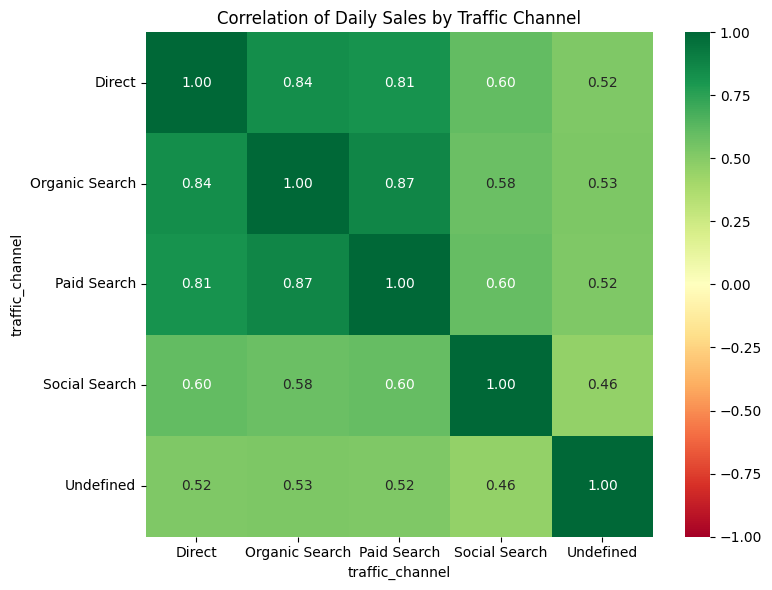

In [ ]:
# Visualize correlations between daily sales by traffic channel
plt.figure(figsize=(8, 6))

sns.heatmap(
    traffic_corr,
    annot=True,
    fmt='.2f',
    cmap='RdYlGn',
    vmin=-1,
    vmax=1,
    center=0
)

plt.title('Correlation of Daily Sales by Traffic Channel')
plt.tight_layout()
plt.show()

In [ ]:
# Calculate Pearson correlation and p-value for each pair of traffic channels
channels = traffic_sales_daily.columns

for i in range(len(channels)):
    for j in range(i + 1, len(channels)):

        r, p = pearsonr(
            traffic_sales_daily[channels[i]],
            traffic_sales_daily[channels[j]]
        )

        print(
            f"{channels[i]} vs {channels[j]}: "
            f"r = {r:.3f}, p-value = {p:.3e}"
        )

Direct vs Organic Search: r = 0.838, p-value = 2.190e-25
Direct vs Paid Search: r = 0.814, p-value = 5.896e-23
Direct vs Social Search: r = 0.604, p-value = 1.832e-10
Direct vs Undefined: r = 0.518, p-value = 1.275e-07
Organic Search vs Paid Search: r = 0.870, p-value = 2.142e-29
Organic Search vs Social Search: r = 0.583, p-value = 1.066e-09
Organic Search vs Undefined: r = 0.526, p-value = 7.228e-08
Paid Search vs Social Search: r = 0.596, p-value = 3.532e-10
Paid Search vs Undefined: r = 0.522, p-value = 9.510e-08
Social Search vs Undefined: r = 0.455, p-value = 5.162e-06


---

## Daily Sales Correlation by Traffic Channel

Продажі за різними каналами трафіку мають **позитивну кореляцію**.

Найсильніший зв’язок спостерігається між **Organic Search та Paid Search** (`r = 0.870`), а також між **Direct та Organic Search** (`r = 0.838`) і **Direct та Paid Search** (`r = 0.814`).

Social Search та Undefined мають слабші взаємозв’язки з іншими каналами, але кореляції залишаються позитивними.

Усі отримані кореляції є **статистично значущими** (`p < 0.05`).

Це означає, що щоденні продажі через різні канали трафіку часто змінюються в одному напрямку, особливо для Direct, Organic Search та Paid Search.

---

In [ ]:
# Identify top 5 product categories by total sales
top_5_categories = (
    df.groupby('product_category')['product_price']
    .sum()
    .sort_values(ascending=False)
    .head(5)
    .index
)

top_5_categories

Index(['Sofas & armchairs', 'Chairs', 'Beds', 'Bookcases & shelving units',
       'Cabinets & cupboards'],
      dtype='object', name='product_category')

In [ ]:
# Calculate daily sales for the top 5 product categories
category_sales_daily = (
    df[df['product_category'].isin(top_5_categories)]
    .groupby(['session_date', 'product_category'])['product_price']
    .sum()
    .unstack(fill_value=0)
)

category_sales_daily.head()

product_category,Beds,Bookcases & shelving units,Cabinets & cupboards,Chairs,Sofas & armchairs
session_date,,,,,
2020-11-01,14041.0,36701.0,13591.5,46006.0,75216.0
2020-11-02,79683.5,40979.0,21623.0,58834.0,79977.5
2020-11-03,66219.5,64360.1,33555.5,61204.0,175594.0
2020-11-04,48939.0,35719.8,19266.0,44113.0,86861.5
2020-11-05,23449.0,40998.8,29235.0,90388.4,137288.0


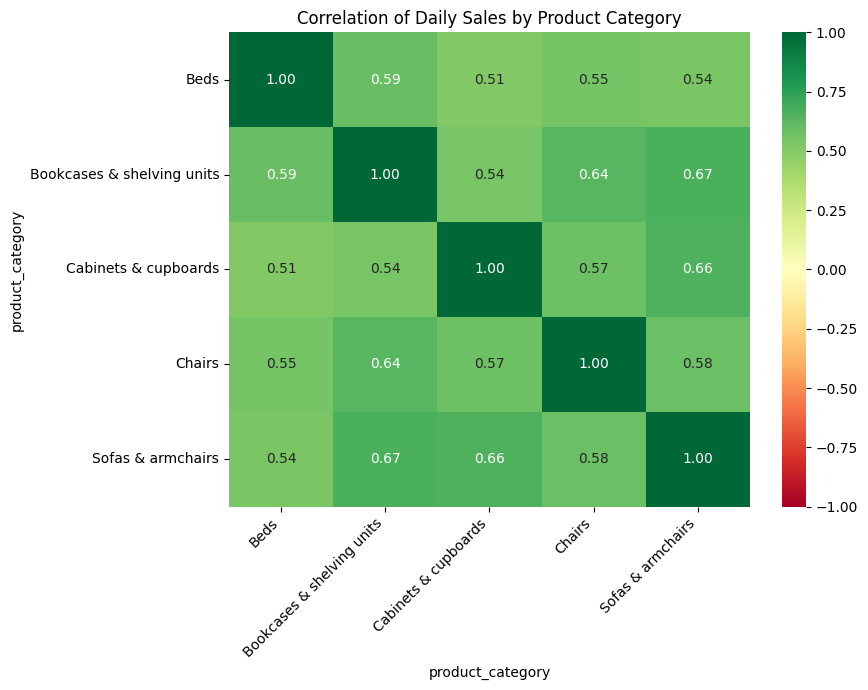

In [ ]:
# Visualize correlations between daily sales of the top 5 product categories
plt.figure(figsize=(9, 7))

sns.heatmap(
    category_corr,
    annot=True,
    fmt='.2f',
    cmap='RdYlGn',
    vmin=-1,
    vmax=1,
    center=0
)

plt.title('Correlation of Daily Sales by Product Category')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [ ]:
# Calculate Pearson correlation and p-value for each pair of product categories
categories = category_sales_daily.columns

for i in range(len(categories)):
    for j in range(i + 1, len(categories)):

        r, p = pearsonr(
            category_sales_daily[categories[i]],
            category_sales_daily[categories[j]]
        )

        print(
            f"{categories[i]} vs {categories[j]}: "
            f"r = {r:.3f}, p-value = {p:.3e}"
        )

Beds vs Bookcases & shelving units: r = 0.593, p-value = 1.155e-09
Beds vs Cabinets & cupboards: r = 0.515, p-value = 2.911e-07
Beds vs Chairs: r = 0.554, p-value = 2.079e-08
Beds vs Sofas & armchairs: r = 0.535, p-value = 7.687e-08
Bookcases & shelving units vs Cabinets & cupboards: r = 0.539, p-value = 5.867e-08
Bookcases & shelving units vs Chairs: r = 0.637, p-value = 2.505e-11
Bookcases & shelving units vs Sofas & armchairs: r = 0.666, p-value = 1.407e-12
Cabinets & cupboards vs Chairs: r = 0.573, p-value = 5.466e-09
Cabinets & cupboards vs Sofas & armchairs: r = 0.658, p-value = 3.415e-12
Chairs vs Sofas & armchairs: r = 0.578, p-value = 3.639e-09


---

## Daily Sales Correlation by Product Category

Продажі топ-5 категорій товарів мають **позитивну кореляцію** між собою.

Найсильніший зв’язок спостерігається між **Bookcases & shelving units** та **Sofas & armchairs** (`r = 0.666`), а також між **Cabinets & cupboards** та **Sofas & armchairs** (`r = 0.658`).

Найслабша кореляція спостерігається між **Beds** та **Cabinets & cupboards** (`r = 0.515`), але вона все одно є помірною.

Усі взаємозв’язки є **статистично значущими** (`p < 0.05`).

Це означає, що щоденні продажі цих категорій мають тенденцію змінюватися в одному напрямку, що може бути пов’язано зі спільними змінами попиту або іншими загальними факторами.

---

In [ ]:
# Calculate daily sales by device type
device_sales_daily = (
    df.groupby(['session_date', 'device_type'])['product_price']
    .sum()
    .unstack(fill_value=0)
)

device_sales_daily.head()

device_type,desktop,mobile,tablet
session_date,,,
2020-11-01,144445.0,99698.5,149.0
2020-11-02,206727.3,137269.5,11510.0
2020-11-03,304473.8,180602.8,13903.0
2020-11-04,212227.7,118324.4,8635.0
2020-11-05,249682.0,138256.0,3338.6


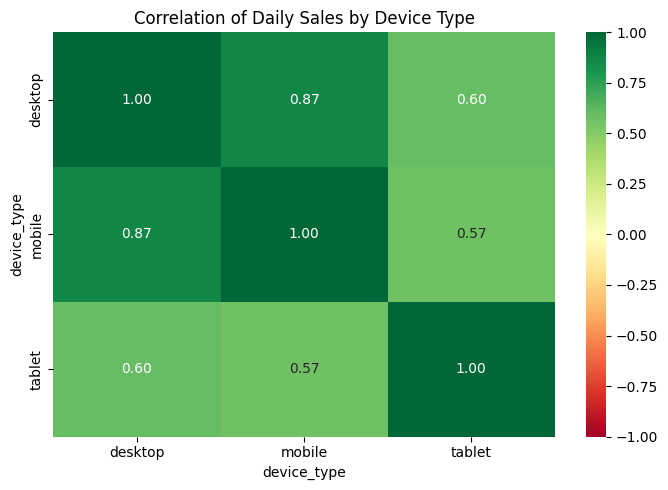

In [ ]:
# Calculate Pearson correlation matrix for device types
device_corr = device_sales_daily.corr()

# Visualize correlations between daily sales by device type
plt.figure(figsize=(7, 5))

sns.heatmap(
    device_corr,
    annot=True,
    fmt='.2f',
    cmap='RdYlGn',
    vmin=-1,
    vmax=1,
    center=0
)

plt.title('Correlation of Daily Sales by Device Type')
plt.tight_layout()
plt.show()

In [ ]:
# Calculate Pearson correlation and p-value for each pair of device types
devices = device_sales_daily.columns

for i in range(len(devices)):
    for j in range(i + 1, len(devices)):

        r, p = pearsonr(
            device_sales_daily[devices[i]],
            device_sales_daily[devices[j]]
        )

        print(
            f"{devices[i]} vs {devices[j]}: "
            f"r = {r:.3f}, p-value = {p:.3e}"
        )

desktop vs mobile: r = 0.873, p-value = 7.720e-30
desktop vs tablet: r = 0.601, p-value = 2.317e-10
mobile vs tablet: r = 0.567, p-value = 3.694e-09


---

## Daily Sales Correlation by Device Type

Продажі за різними типами пристроїв мають **позитивну кореляцію** між собою.

Найсильніший зв’язок спостерігається між **desktop та mobile** (`r = 0.873`), що означає, що їхні щоденні продажі змінюються дуже схожим чином.

Зв’язок між **desktop та tablet** (`r = 0.601`) і між **mobile та tablet** (`r = 0.567`) є помірним.

Усі отримані кореляції є **статистично значущими** (`p < 0.05`).

Це означає, що щоденні продажі через різні типи пристроїв часто змінюються в одному напрямку, особливо для desktop і mobile.

---

# 7. Statistical Group Comparison

In [ ]:
# Create user type based on registration status
df['user_type'] = df['account_id'].notna().map({
    True: 'Registered',
    False: 'Unregistered'
})

In [ ]:
# Calculate daily sales for registered and unregistered users
daily_sales_by_user = (
    df.groupby(['session_date', 'user_type'])['product_price']
    .sum()
    .unstack(fill_value=0)
)

daily_sales_by_user.head()

user_type,Registered,Unregistered
session_date,,
2020-11-01,21547.0,222745.5
2020-11-02,44956.8,310550.0
2020-11-03,29150.5,469829.1
2020-11-04,20982.2,318204.9
2020-11-05,25334.6,365942.0


In [ ]:
# Calculate daily sales for registered and unregistered users
daily_sales_by_user = (
    df.groupby(['session_date', 'user_type'])['product_price']
    .sum()
    .unstack(fill_value=0)
)

daily_sales_by_user.head()

user_type,Registered,Unregistered
session_date,,
2020-11-01,21547.0,222745.5
2020-11-02,44956.8,310550.0
2020-11-03,29150.5,469829.1
2020-11-04,20982.2,318204.9
2020-11-05,25334.6,365942.0


In [ ]:
# Create two samples of daily sales
registered_sales = daily_sales_by_user['Registered']
unregistered_sales = daily_sales_by_user['Unregistered']

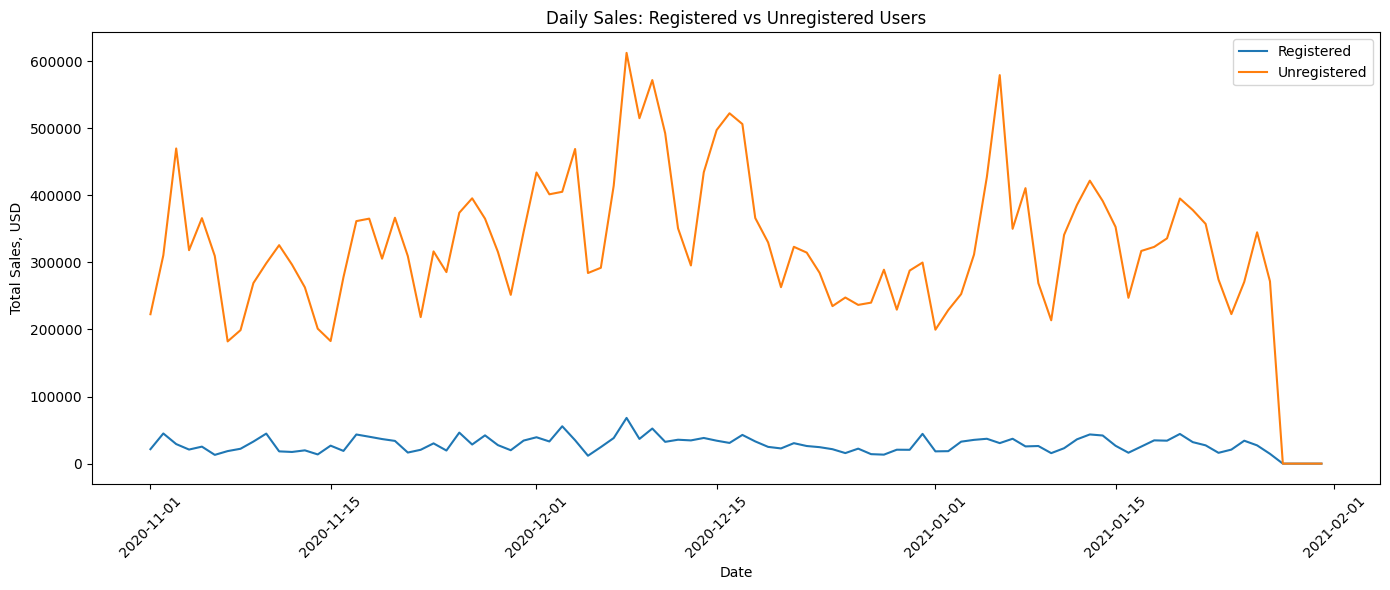

In [ ]:
# Visualize daily sales for registered and unregistered users
plt.figure(figsize=(14, 6))

plt.plot(
    daily_sales_by_user.index,
    daily_sales_by_user['Registered'],
    label='Registered'
)

plt.plot(
    daily_sales_by_user.index,
    daily_sales_by_user['Unregistered'],
    label='Unregistered'
)

plt.title('Daily Sales: Registered vs Unregistered Users')
plt.xlabel('Date')
plt.ylabel('Total Sales, USD')
plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
# Compare descriptive statistics of daily sales
print("Registered users:")
print(registered_sales.describe())

print("\nUnregistered users:")
print(unregistered_sales.describe())

Registered users:
count       92.000000
mean     28070.853261
std      12124.817697
min          0.000000
25%      19938.250000
50%      27233.500000
75%      35478.600000
max      68151.100000
Name: Registered, dtype: float64

Unregistered users:
count        92.000000
mean     319447.963043
std      113764.392969
min           0.000000
25%      263005.700000
50%      315170.750000
75%      375010.750000
max      612358.400000
Name: Unregistered, dtype: float64


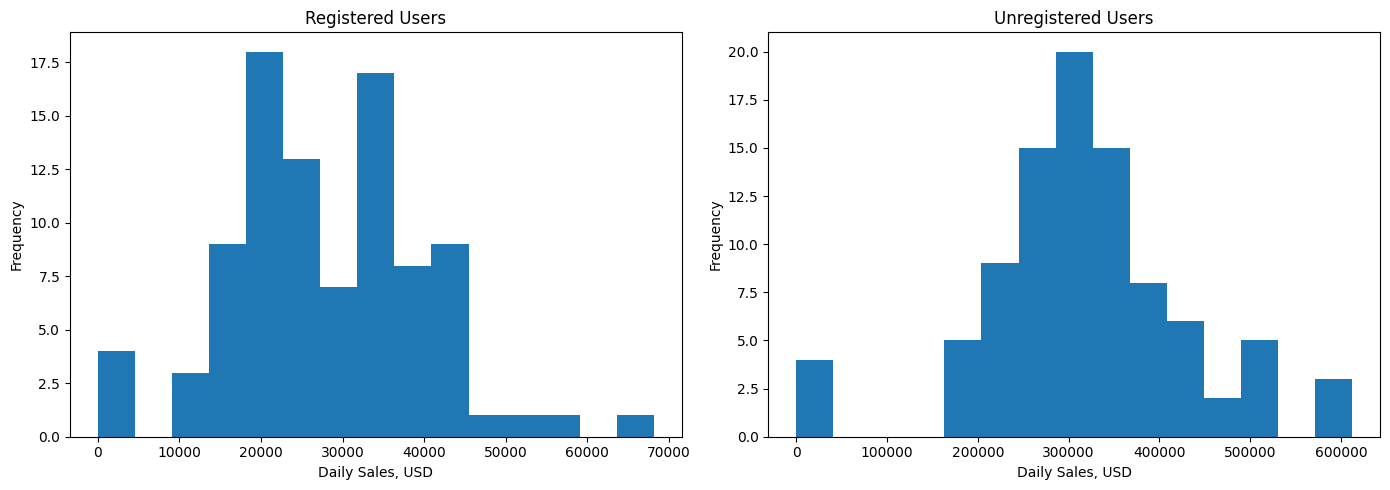

In [ ]:
# Visualize distributions of daily sales
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(registered_sales, bins=15)
axes[0].set_title('Registered Users')
axes[0].set_xlabel('Daily Sales, USD')
axes[0].set_ylabel('Frequency')

axes[1].hist(unregistered_sales, bins=15)
axes[1].set_title('Unregistered Users')
axes[1].set_xlabel('Daily Sales, USD')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

In [ ]:
# Test normality of both samples
from scipy.stats import shapiro

stat_reg, p_reg = shapiro(registered_sales)
stat_unreg, p_unreg = shapiro(unregistered_sales)

print(f"Registered: p-value = {p_reg:.5f}")
print(f"Unregistered: p-value = {p_unreg:.5f}")

Registered: p-value = 0.14817
Unregistered: p-value = 0.00122


In [ ]:
# Check normality of paired differences
sales_difference = unregistered_sales - registered_sales

stat_diff, p_diff = shapiro(sales_difference)

print(f"Difference p-value: {p_diff:.5f}")

Difference p-value: 0.00089


In [ ]:
# Compare paired daily sales using Wilcoxon signed-rank test
from scipy.stats import wilcoxon

stat, p_value = wilcoxon(
    registered_sales,
    unregistered_sales
)

print(f"Wilcoxon statistic: {stat:.3f}")
print(f"P-value: {p_value:.3e}")

Wilcoxon statistic: 0.000
P-value: 3.732e-16


---

## Registered vs Unregistered Users

Розподіл різниць між щоденними продажами зареєстрованих і незареєстрованих користувачів не є нормальним (`p = 0.00089`), тому для порівняння було використано **Wilcoxon signed-rank test**.

Результат тесту показав статистично значущу різницю між групами:

- Wilcoxon statistic: **0.000**
- p-value: **3.732e-16**

Отже, щоденні продажі зареєстрованих і незареєстрованих користувачів **статистично значущо відрізняються**.

Незареєстровані користувачі мають значно вищі щоденні продажі, що також узгоджується з описовою статистикою.

---

In [ ]:
# Calculate daily number of sessions by traffic channel
daily_sessions_by_channel = (
    df.groupby(['session_date', 'traffic_channel'])['session_id']
    .nunique()
    .unstack(fill_value=0)
)

daily_sessions_by_channel.head()

traffic_channel,Direct,Organic Search,Paid Search,Social Search,Undefined
session_date,,,,,
2020-11-01,608,920,706,214,128
2020-11-02,810,1242,970,315,262
2020-11-03,1216,1871,1367,392,327
2020-11-04,935,1425,1145,368,311
2020-11-05,845,1293,917,346,342


In [ ]:
# Compare descriptive statistics of daily sessions by traffic channel
daily_sessions_by_channel.describe()

traffic_channel,Direct,Organic Search,Paid Search,Social Search,Undefined
count,92.000000,92.000000,92.000000,92.000000,92.000000
mean,884.586957,1352.445652,1025.445652,303.413043,233.510870
std,220.225267,336.572261,254.421100,88.127923,83.634276
min,481.000000,733.000000,578.000000,137.000000,86.000000
25%,744.000000,1117.250000,860.250000,235.500000,160.750000
50%,869.500000,1329.000000,989.000000,308.000000,229.000000
75%,1004.750000,1558.750000,1171.750000,358.250000,293.250000
max,1668.000000,2589.000000,1959.000000,561.000000,435.000000


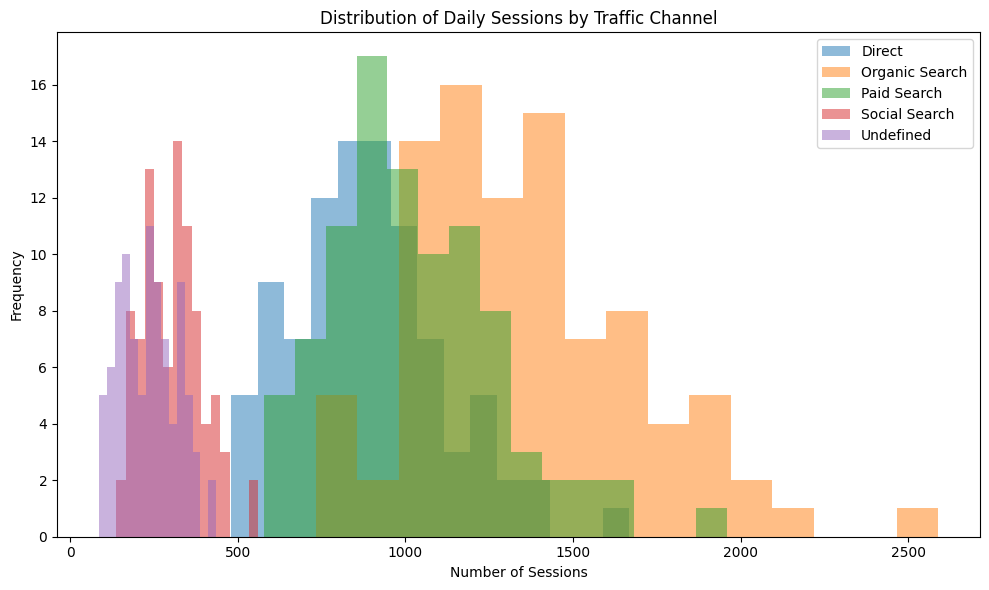

In [ ]:
# Visualize distributions of daily sessions by traffic channel
plt.figure(figsize=(10, 6))

for channel in daily_sessions_by_channel.columns:
    plt.hist(
        daily_sessions_by_channel[channel],
        bins=15,
        alpha=0.5,
        label=channel
    )

plt.title('Distribution of Daily Sessions by Traffic Channel')
plt.xlabel('Number of Sessions')
plt.ylabel('Frequency')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
# Test normality of daily sessions for each traffic channel
from scipy.stats import shapiro

for channel in daily_sessions_by_channel.columns:
    stat, p = shapiro(daily_sessions_by_channel[channel])

    print(
        f"{channel}: "
        f"p-value = {p:.5f}"
    )

Direct: p-value = 0.03428
Organic Search: p-value = 0.01227
Paid Search: p-value = 0.01083
Social Search: p-value = 0.14127
Undefined: p-value = 0.05456


In [ ]:
# Compare daily sessions between traffic channels using Friedman test
from scipy.stats import friedmanchisquare

stat, p_value = friedmanchisquare(
    *[
        daily_sessions_by_channel[channel]
        for channel in daily_sessions_by_channel.columns
    ]
)

print(f"Friedman statistic: {stat:.3f}")
print(f"P-value: {p_value:.3e}")

Friedman statistic: 368.000
P-value: 2.275e-78


---

## Daily Sessions by Traffic Channel

Оскільки щоденні значення для різних каналів трафіку належать тим самим датам, для порівняння було використано **Friedman test**.

Результат тесту:

- Friedman statistic: **368.000**
- p-value: **2.275e-78**

Отже, між каналами трафіку є **статистично значущі відмінності** у кількості щоденних сесій (`p < 0.05`).

За описовою статистикою найбільшу середню кількість сесій має **Organic Search**, далі йдуть **Paid Search** та **Direct**. Найменші показники мають **Social Search** та **Undefined**.

---

In [ ]:
# Calculate total and Organic Search sessions for Europe and Americas
organic_sessions = (
    df[df['continent'].isin(['Europe', 'Americas'])]
    .groupby('continent')
    .agg(
        total_sessions=('session_id', 'nunique'),
        organic_sessions=(
            'traffic_channel',
            lambda x: (x == 'Organic Search').sum()
        )
    )
)

organic_sessions

,total_sessions,organic_sessions
continent,,
Americas,193179,68671
Europe,65135,23195


In [ ]:
# Calculate the share of Organic Search sessions
organic_sessions['organic_share'] = (
    organic_sessions['organic_sessions'] /
    organic_sessions['total_sessions']
)

organic_sessions

,total_sessions,organic_sessions,organic_share
continent,,,
Americas,193179,68671,0.355479
Europe,65135,23195,0.356107


In [ ]:
# Compare Organic Search proportions using a two-proportion z-test
from statsmodels.stats.proportion import proportions_ztest

count = [
    organic_sessions.loc['Europe', 'organic_sessions'],
    organic_sessions.loc['Americas', 'organic_sessions']
]

nobs = [
    organic_sessions.loc['Europe', 'total_sessions'],
    organic_sessions.loc['Americas', 'total_sessions']
]

z_stat, p_value = proportions_ztest(count, nobs)

print(f"Z-statistic: {z_stat:.3f}")
print(f"P-value: {p_value:.3e}")

Z-statistic: 0.290
P-value: 7.722e-01


---

## Organic Search Share: Europe vs Americas

Частка сесій з Organic Search майже однакова в обох регіонах:

- Americas: **35.55%**
- Europe: **35.61%**

Для порівняння часток було використано **two-proportion z-test**.

Результат тесту:

- Z-statistic: **0.290**
- p-value: **0.772**

Оскільки `p > 0.05`, статистично значущої різниці між часткою Organic Search у Europe та Americas **не виявлено**.

---

In [ ]:
# Select users with known subscription status
subscription_data = df[df['is_unsubscribed'].notna()].copy()

# Create user-level sales
user_sales = (
    subscription_data
    .groupby(['account_id', 'is_unsubscribed'])['product_price']
    .sum()
    .reset_index(name='total_sales')
)

user_sales.head()

,account_id,is_unsubscribed,total_sales
0,636133,1,0.0
1,636135,1,0.0
2,636136,1,0.0
3,636138,0,395.0
4,636139,0,125.0


In [ ]:
# Create two groups
subscribed_sales = user_sales[
    user_sales['is_unsubscribed'] == 0
]['total_sales']

unsubscribed_sales = user_sales[
    user_sales['is_unsubscribed'] == 1
]['total_sales']

In [ ]:
# Descriptive statistics
print("Subscribed users:")
print(subscribed_sales.describe())

print("\nUnsubscribed users:")
print(unsubscribed_sales.describe())

Subscribed users:
count    23210.000000
mean        92.666820
std        502.990071
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max       8900.000000
Name: total_sales, dtype: float64

Unsubscribed users:
count    4735.000000
mean       91.176684
std       488.401595
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max      8900.000000
Name: total_sales, dtype: float64


In [ ]:
from scipy.stats import shapiro

# Check normality
stat_sub, p_sub = shapiro(subscribed_sales)
stat_unsub, p_unsub = shapiro(unsubscribed_sales)

print(f"Subscribed p-value: {p_sub:.5f}")
print(f"Unsubscribed p-value: {p_unsub:.5f}")

Subscribed p-value: 0.00000
Unsubscribed p-value: 0.00000


/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 23210.
  res = hypotest_fun_out(*samples, **kwds)


In [ ]:
from scipy.stats import mannwhitneyu

# Compare sales between subscribed and unsubscribed users
stat, p_value = mannwhitneyu(
    subscribed_sales,
    unsubscribed_sales,
    alternative='two-sided'
)

print(f"Mann-Whitney U statistic: {stat:.3f}")
print(f"P-value: {p_value:.3e}")

Mann-Whitney U statistic: 55266534.000
P-value: 2.279e-01


---

### Subscribed vs Unsubscribed Users

Для порівняння продажів між підписаними та відписаними користувачами було використано **Mann–Whitney U test**, оскільки розподіли в обох групах не є нормальними.

Результат тесту:

- Mann–Whitney U statistic: **55,266,534**
- p-value: **0.228**

Оскільки `p > 0.05`, статистично значущої різниці у продажах між підписаними та відписаними користувачами **не виявлено**.

Отже, у межах цього датасету статус підписки на розсилку не пов’язаний зі статистично значущими відмінностями у продажах на користувача.

---

In [ ]:
# Create purchase flag
df['has_purchase'] = df['product_name'].notna()

In [ ]:
# Select registered users with known email verification status
verified_data = df[df['is_verified'].notna()]

In [ ]:
# Create contingency table for email verification and purchase
verification_purchase_table = pd.crosstab(
    verified_data['is_verified'],
    verified_data['has_purchase'])

verification_purchase_table

has_purchase,False,True
is_verified,,
0,7117,792
1,18047,1989


In [ ]:
# Calculate purchase rate by email verification status
purchase_rate_by_verification = (
    verified_data
    .groupby('is_verified')['has_purchase']
    .mean() * 100)

purchase_rate_by_verification

,has_purchase
is_verified,
0,10.013908
1,9.927131


In [ ]:
# Test association between email verification and purchase
from scipy.stats import chi2_contingency

chi2, p_value, dof, expected = chi2_contingency(
    verification_purchase_table
)

print(f"Chi-square statistic: {chi2:.3f}")
print(f"P-value: {p_value:.3e}")

Chi-square statistic: 0.038
P-value: 8.445e-01


---

## Purchases by Email Verification Status

Для перевірки того, чи відрізняється здійснення покупок між користувачами з підтвердженим і непідтвердженим email, було використано **Chi-square test of independence**.

Частка сесій із покупкою становить:

- Unverified users: **10.01%**
- Verified users: **9.93%**

Результат тесту:

- Chi-square statistic: **0.038**
- p-value: **0.845**

Оскільки `p > 0.05`, статистично значущої різниці в здійсненні покупок між користувачами з підтвердженим і непідтвердженим email **не виявлено**.

Отже, у межах цього датасету статус підтвердження email не пов’язаний зі статистично значущими відмінностями у факті здійснення покупки.

---

---

# Final Analytical Report: Sales Performance, User Behavior and Statistical Insights


### 1. Data Quality and Structure

Після об’єднання таблиць датасет містить **349,545 унікальних сесій** за період з **1.11.2020 до 31.01.2021**.

Повних дублікатів у даних не виявлено.

Пропущені значення мають переважно логічне пояснення:

- відсутність `account_id` означає, що користувач не був зареєстрований;
- відсутність інформації про товар означає, що сесія не завершилася покупкою;
- пропуски у `browser_language` були замінені на `unknown`.

Таким чином, дані були очищені без штучної заміни значень, які несуть бізнес-сенс.

---

### 2. Geography of Sales

Основним регіоном за обсягом продажів є **Americas**.

Загальний обсяг продажів:

- Americas — **\$17.67M**
- Asia — **\$7.60M**
- Europe — **\$5.93M**

Americas також мають найбільшу кількість покупок — **18,553**.

У розрізі країн абсолютним лідером є **United States**:

- продажі — **\$13.94M**
- кількість покупок — **14,673**

Далі йдуть India, Canada, United Kingdom та France.

Це показує, що значна частина бізнесу компанії концентрується на американському ринку, особливо у США.

---

### 3. Product Categories

Найбільший обсяг продажів формує категорія **Sofas & armchairs — \$8.39M**.

Далі йдуть:

- Chairs — **\$6.15M**
- Beds — **\$4.92M**
- Bookcases & shelving units — **\$3.64M**
- Cabinets & cupboards — **\$2.34M**

У United States структура продажів дуже схожа до глобальної: найбільший внесок також формують Sofas & armchairs, Chairs та Beds.

Це означає, що основні товарні категорії мають стабільно високий попит як глобально, так і на ключовому ринку компанії.

---

### 4. Device Performance

Найбільшу частку продажів генерує **desktop — 59.0%**.

Структура продажів за пристроями:

- Desktop — **59.0%**
- Mobile — **38.7%**
- Tablet — **2.3%**

При цьому конверсія між desktop та mobile майже однакова:

- Desktop — **9.64%**
- Mobile — **9.55%**
- Tablet — **9.21%**

Отже, перевага desktop у загальному обсязі продажів пояснюється не значно кращою конверсією, а більшою кількістю сесій.

**Mobile** також є важливим каналом взаємодії з користувачами та генерує майже **39%** продажів.

---

### 5. Traffic Channels

Найбільшу частку продажів забезпечує **Organic Search — 35.76%**.

Далі йдуть:

- Paid Search — **26.62%**
- Direct — **23.44%**
- Social Search — **7.92%**
- Undefined — **6.26%**

Organic Search також має найбільшу кількість сесій.

Комбінація **Organic Search + Desktop** є найсильнішою:

- **72,622 сесії**
- приблизно **\$6.79M продажів**

Це робить органічний пошук одним із ключових джерел трафіку та доходу компанії.

Середній чек у різних каналах є досить стабільним і знаходиться приблизно в межах **\$932–972**, тому різниця в загальних продажах між каналами значною мірою пояснюється обсягом трафіку.

---

### 6. Registered and Unregistered Users

Зареєстровані користувачі становлять відносно невелику частину загальної кількості сесій.

Серед зареєстрованих користувачів:

- **71.7%** мають підтверджений email;
- **16.9%** відписалися від комунікацій.

Найбільше зареєстрованих користувачів знаходиться у United States — **12,384**.

Загальний обсяг продажів:

- Registered users — **\$2.58M**
- Unregistered users — **\$29.39M**

Ця різниця значною мірою пояснюється тим, що незареєстрованих користувачів у датасеті значно більше.

Статистичний аналіз також показав, що щоденні продажі зареєстрованих та незареєстрованих користувачів **статистично значущо відрізняються**.

---

### 7. Sales Dynamics

Щоденні продажі характеризуються суттєвими коливаннями.

Найвищий рівень продажів було зафіксовано **8 грудня 2020 року — \$680.5K**.

Також високі значення спостерігалися 10 грудня 2020 року та 6 січня 2021 року.

За днями тижня найбільший загальний обсяг продажів припадає на:

- Wednesday — **\$5.47M**
- Tuesday — **\$5.46M**
- Thursday — **\$4.94M**

Найнижчі загальні показники спостерігаються у Saturday та Sunday.

Це може свідчити про певний тижневий патерн, однак через короткий період спостереження його слід трактувати обережно.

Наприкінці січня є кілька днів із нульовими продажами, які можуть бути пов’язані з неповнотою даних, тому вони не повинні трактуватися як реальне різке падіння бізнесу.

---

### 8. Relationship Between Sessions and Sales

Між кількістю щоденних сесій і загальними продажами виявлено **сильний позитивний зв’язок**:

- Pearson correlation: **r = 0.791**
- `p < 0.05`

Тобто у дні з більшою кількістю сесій зазвичай спостерігається вищий обсяг продажів.

Це підтверджує важливість залучення трафіку для формування виручки.

Водночас кореляція не означає причинно-наслідкового зв’язку.

---

### 9. Correlations Between Regions, Channels and Categories

Продажі в Americas, Asia та Europe мають сильну позитивну кореляцію:

- Americas vs Asia — **r = 0.792**
- Americas vs Europe — **r = 0.771**
- Asia vs Europe — **r = 0.768**

Це означає, що продажі в різних регіонах часто змінюються синхронно.

Сильна позитивна кореляція також спостерігається між основними каналами трафіку.

Найсильніший зв’язок:

- Organic Search vs Paid Search — **r = 0.870**
- Direct vs Organic Search — **r = 0.838**
- Direct vs Paid Search — **r = 0.814**

Серед товарних категорій усі топ-5 категорій також мають позитивні статистично значущі кореляції.

Це може вказувати на вплив спільних факторів попиту, сезонності або маркетингової активності.

---

### 10. Device Sales Dynamics

Щоденні продажі через різні пристрої також рухаються в одному напрямку.

Кореляції:

- Desktop vs Mobile — **r = 0.873**
- Desktop vs Tablet — **r = 0.601**
- Mobile vs Tablet — **r = 0.567**

Найсильніший зв’язок спостерігається між desktop та mobile.

Це означає, що зміни загального попиту одночасно відображаються на різних пристроях, а не лише на одному каналі взаємодії.

---

### 11. Differences Between Traffic Channels

Кількість щоденних сесій статистично значущо відрізняється між каналами трафіку.

Для аналізу було використано **Friedman test**, оскільки всі канали порівнювалися для тих самих дат.

Результат:

- Friedman statistic: **368.000**
- p-value: **2.275e-78**

Отже, різниця між каналами є статистично значущою.

Найбільшу середню кількість сесій має **Organic Search**, далі йдуть Paid Search та Direct.

---

### 12. Organic Traffic in Europe and Americas

Частка Organic Search майже однакова в Europe та Americas:

- Europe — **35.61%**
- Americas — **35.55%**

Two-proportion z-test показав:

- Z-statistic: **0.290**
- p-value: **0.772**

Статистично значущої різниці не виявлено.

Отже, структура органічного трафіку в Europe та Americas є дуже схожою.

---

### 13. Subscribed vs Unsubscribed Users

Для порівняння продажів між підписаними та відписаними користувачами було використано **Mann–Whitney U test**, оскільки розподіли в обох групах не є нормальними.

Результат тесту:

- Mann–Whitney U statistic: **55,266,534**
- p-value: **0.228**

Оскільки `p > 0.05`, статистично значущої різниці у продажах між підписаними та відписаними користувачами **не виявлено**.

Отже, у межах цього датасету статус підписки на розсилку не пов’язаний зі статистично значущими відмінностями у продажах на користувача.

---

### 14. Email Verification and Purchases

Частка сесій із покупкою майже однакова для користувачів із підтвердженим і непідтвердженим email:

- Unverified — **10.01%**
- Verified — **9.93%**

Chi-square test показав:

- Chi-square statistic: **0.038**
- p-value: **0.845**

Таким чином, статистично значущої різниці у здійсненні покупок між цими групами **не виявлено**.

Отже, у межах цього датасету підтвердження email не пов’язане з вищою частотою здійснення покупки.

---

## Overall Business Conclusion

Основним ринком компанії є **Americas**, а ключовою країною — **United States**, які формують найбільшу частину продажів та покупок.

Найсильнішими товарними категоріями є **Sofas & armchairs, Chairs та Beds**.

Основним джерелом трафіку є **Organic Search**, який генерує найбільшу кількість сесій та найбільшу частку продажів.

**Desktop** залишається головним пристроєм для продажів, однак mobile також має дуже значний внесок і майже таку саму конверсію.

Продажі сильно пов’язані з обсягом трафіку: збільшення кількості сесій супроводжується зростанням продажів.

Водночас продажі в різних регіонах, каналах, категоріях та пристроях мають схожу динаміку, що може свідчити про вплив спільних факторів попиту.

Не всі характеристики користувачів мають значний вплив на покупки. Зокрема, статус підтвердження email не показав статистично значущої різниці.

---

## Recommendations

- **Продовжувати інвестувати в Organic Search**, оскільки цей канал генерує найбільшу кількість сесій та найбільшу частку продажів.

- **Підтримувати сильну присутність на ринку United States**, який є основним джерелом продажів компанії.

- **Забезпечувати достатню наявність категорій Sofas & armchairs, Chairs та Beds**, оскільки вони формують найбільшу частину виручки.

- **Не зосереджуватися лише на desktop**. Mobile генерує майже 39% продажів і має практично таку саму конверсію, тому mobile experience також має бути одним із пріоритетів.

- **Працювати над збільшенням якісного трафіку**, оскільки між кількістю сесій та продажами існує сильний позитивний зв’язок.

- **Окремо дослідити причини високої концентрації продажів у Americas та United States**, щоб оцінити потенціал інших регіонів і зменшити залежність від одного ринку.

- **Не використовувати підтвердження email як основний індикатор купівельної поведінки**, оскільки статистично значущої різниці між verified та unverified users не виявлено.

- **Дослідити причини відмінностей між каналами трафіку**, особливо між Organic Search, Paid Search та Direct, оскільки їхня кількість сесій статистично значущо відрізняється.

- **Перевірити якість даних наприкінці досліджуваного періоду**, оскільки кілька останніх днів мають нульові продажі та можуть бути неповними.